# Swiss lake water levels – daily climatology

Downloads the **daily mean water level** (`W`, m a.s.l.) of every active FOEN lake station from the
[BAFU data platform](https://data.bafu.admin.ch/en/) GraphQL API, and plots for each station the
day-of-year climatology (mean, ±1 std, min–max envelope) with the current year highlighted.

* Data are cached in `data/` as CSV; re-running only fetches the most recent days.
* Figures are written to `figures/`.
* A query is capped at 10 000 rows, so each station is fetched in 20-year windows.

In [1]:
import re
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timezone
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

ENDPOINT = "https://data.bafu.admin.ch/api"
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

CURRENT_YEAR = date.today().year
# Climatology period (inclusive). None = start of record. Regulation changes (e.g. Jura water
# corrections) can make early records unrepresentative; set e.g. 1991 to restrict.
CLIM_START_YEAR = None
CLIM_END_YEAR = CURRENT_YEAR - 1

WINDOW_YEARS = 20          # 20 years of daily values ≈ 7300 rows < 10 000 row cap
REFRESH_ALL = False        # True = ignore cache and re-download everything
REPORT_END = pd.Timestamp("2026-09-28")  # freeze the analysis on this day (for the report); None = latest data
MAX_WORKERS = 4            # concurrent stations; API allows 500 requests / 5 min per IP

# Stations are selected by water body name; adjust these if needed.
LAKE_PATTERN = re.compile(r"see\b|^lac |^lago |^lej ", re.IGNORECASE)
EXCLUDE_STATIONS = set()   # e.g. {"2066"}
INCLUDE_STATIONS = set()   # stations to add even if the pattern does not match

# English short names used on the report figures
EN = {"Zürichsee": "Zurich", "Zürichsee (Obersee)": "Zurich (Obersee)", "Lac Léman": "Geneva",
      "Bodensee (Obersee)": "Constance", "Bodensee (Untersee)": "Constance (Untersee)", "Bodensee": "Constance",
      "Vierwaldstättersee": "Lucerne", "Lago Maggiore": "Maggiore", "Lago di Lugano": "Lugano",
      "Lac de Neuchâtel": "Neuchâtel", "Bielersee": "Biel", "Murtensee": "Murten", "Thunersee": "Thun",
      "Brienzersee": "Brienz", "Walensee": "Walensee", "Zugersee": "Zug", "Ägerisee": "Ägeri",
      "Sempachersee": "Sempach", "Hallwilersee": "Hallwil", "Baldeggersee": "Baldegg", "Lauerzersee": "Lauerz",
      "Sarnersee": "Sarnen", "Silsersee": "Sils", "Silvaplanersee": "Silvaplana", "St. Moritzersee": "St. Moritz",
      "Lac de Joux": "Joux", "Lac des Brenets": "Brenets",
      "Jura lakes (Neuchâtel, Biel, Murten)": "Jura lakes", "Upper Engadin lakes (Sils, Silvaplana, St. Moritz)": "Engadin lakes"}


In [2]:
# Report figures are also saved as "<name>_large.png" with all text enlarged (for the large font report)
import matplotlib
import matplotlib.figure as mfig

REPORT_FIGS = {"weather_2026.png", "unusualness_per_lake.png", "map_2026.png", "inflow_vs_glacier.png",
               "anomaly_lakes.png", "validation_silsersee.png", "geneva_zurich.png", "surface_temperature.png",
               "evaporation_map.png", "evaporation_share.png"}
LARGE_FONT_SCALE = 1.6
TICK_FONT_SCALE = 1.3      # tick labels grow less, to avoid crowded axes

if not hasattr(mfig.Figure, "_orig_savefig"):
    mfig.Figure._orig_savefig = mfig.Figure.savefig
    mfig.Figure._orig_tight_layout = mfig.Figure.tight_layout

def _tight_layout(self, *args, **kwargs):
    self._tight_kwargs = kwargs
    return mfig.Figure._orig_tight_layout(self, *args, **kwargs)

def _savefig(self, fname, *args, **kwargs):
    out = mfig.Figure._orig_savefig(self, fname, *args, **kwargs)
    path = Path(fname)
    if path.name in REPORT_FIGS:
        ticks = {id(t) for ax in self.axes for t in ax.get_xticklabels() + ax.get_yticklabels()}
        for t in self.findobj(matplotlib.text.Text):
            t.set_fontsize(t.get_fontsize() * (TICK_FONT_SCALE if id(t) in ticks else LARGE_FONT_SCALE))
        if hasattr(self, "_tight_kwargs"):
            mfig.Figure._orig_tight_layout(self, **self._tight_kwargs)
        mfig.Figure._orig_savefig(self, path.with_name(path.stem + "_large" + path.suffix), *args,
                                  **{**kwargs, "bbox_inches": "tight"})
    return out

mfig.Figure.tight_layout = _tight_layout
mfig.Figure.savefig = _savefig

## API helper

In [3]:
def gql(query, variables=None, retries=5):
    """POST a GraphQL query; retry on rate limiting / transient errors."""
    for attempt in range(retries):
        try:
            r = requests.post(ENDPOINT, json={"query": query, "variables": variables or {}}, timeout=120)
            if r.status_code in (403, 429, 500, 502, 503, 504):
                raise requests.HTTPError(f"HTTP {r.status_code}")
            r.raise_for_status()
            payload = r.json()
            if payload.get("errors"):
                raise RuntimeError(payload["errors"])
            return payload["data"]["water"]["observations"]
        except (requests.RequestException, ValueError) as err:
            if attempt == retries - 1:
                raise
            time.sleep(5 * 2 ** attempt)

## Lake stations

In [4]:
stations = pd.DataFrame(gql("""
{ water { observations {
    stations(where: {status: {_eq: "Aufgebaut"}}, limit: 10000) {
      no name riverName latitude longitude coverageFrom coverageTo
    }
} } }
""")["stations"])

is_lake = stations["riverName"].fillna("").str.contains(LAKE_PATTERN) | stations["no"].isin(INCLUDE_STATIONS)
lakes = (stations[is_lake & ~stations["no"].isin(EXCLUDE_STATIONS)]
         .rename(columns={"riverName": "lake"})
         .sort_values(["lake", "name"])
         .reset_index(drop=True))
lakes["coverageFrom"] = pd.to_datetime(lakes["coverageFrom"])
print(f"{len(lakes)} lake stations")
lakes[["no", "lake", "name", "coverageFrom"]]

32 lake stations


,no,lake,name,coverageFrom
0,2137,Baldeggersee,Gelfingen,1919-01-01 00:00:00+00:00
1,2208,Bielersee,"Ligerz, Klein Twann",1890-01-01 00:00:00+00:00
2,2032,Bodensee (Obersee),Romanshorn,1881-01-01 00:00:00+00:00
3,2043,Bodensee (Untersee),Berlingen,1886-01-01 00:00:00+00:00
4,2023,Brienzersee,Ringgenberg,1868-01-01 00:00:00+00:00
5,2097,Hallwilersee,Meisterschwanden,1905-01-01 00:00:00+00:00
6,2026,Lac Léman,Chillon,1874-01-01 00:00:00+00:00
7,2028,Lac Léman,"Genève, Sécheron",1886-01-01 00:00:00+00:00
8,2027,Lac Léman,St-Prex,1930-01-01 00:00:00+00:00
9,2007,Lac de Joux,Le Pont,1982-01-01 00:00:00+00:00


## Download daily mean water level (cached)

In [5]:
DAILY_QUERY = """
query ($no: String!, $from: AWSDateTime!, $to: AWSDateTime!) {
  water { observations {
    data_1day_mean(
      where: {station: {no: {_eq: $no}}, parameterName: {_eq: "W"},
              timestamp: {_gte: $from, _lt: $to}},
      limit: 10000
    ) { timestamp value releaseState }
  } }
}
"""

def fmt(ts):
    return ts.strftime("%Y-%m-%dT%H:%M:%SZ")

def fetch_range(no, start, end):
    rows = []
    cursor = start
    while cursor < end:
        nxt = min(cursor + pd.DateOffset(years=WINDOW_YEARS), end)
        rows += gql(DAILY_QUERY, {"no": no, "from": fmt(cursor), "to": fmt(nxt)})["data_1day_mean"]
        cursor = nxt
    if not rows:
        return pd.DataFrame(columns=["value", "releaseState"], index=pd.DatetimeIndex([], name="date"))
    df = pd.DataFrame(rows)
    # Daily values are stamped at local midnight (23:00/22:00 UTC) -> convert to local calendar date
    df["date"] = (pd.to_datetime(df["timestamp"], utc=True)
                  .dt.tz_convert("Europe/Zurich").dt.tz_localize(None).dt.normalize())
    return df.drop(columns="timestamp").set_index("date").sort_index()

def load_station(row):
    path = DATA_DIR / f"W_daily_{row.no}.csv"
    end = pd.Timestamp(datetime.now(timezone.utc)).tz_localize(None) + pd.Timedelta(days=1)
    if path.exists() and not REFRESH_ALL:
        old = pd.read_csv(path, index_col="date", parse_dates=["date"])
        start = (old.index.max() - pd.Timedelta(days=30)) if len(old) else row.coverageFrom.tz_localize(None)
        new = fetch_range(row.no, start, end)
        df = pd.concat([old, new])
    else:
        df = fetch_range(row.no, row.coverageFrom.tz_localize(None), end)
    df = df[~df.index.duplicated(keep="last")].sort_index()
    df.to_csv(path)
    return row.no, df

t0 = time.time()
with ThreadPoolExecutor(MAX_WORKERS) as pool:
    series = dict(pool.map(load_station, lakes.itertuples()))
if REPORT_END is not None:
    series = {no: df[:REPORT_END] for no, df in series.items()}
print(f"downloaded in {time.time() - t0:.0f} s")

lakes["n_days"] = lakes["no"].map(lambda n: len(series[n]))
lakes["first"] = lakes["no"].map(lambda n: series[n].index.min())
lakes["last"] = lakes["no"].map(lambda n: series[n].index.max())
lakes[["no", "lake", "name", "n_days", "first", "last"]]

/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])


/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a f

/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])


/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])


/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])


/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])


/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a f

/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([old, new])
/var/folders/bz/6fwq95z91450fyw8y89913_w0000gr/T/ipykernel_44011/1335783211.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a f

downloaded in 7 s


,no,lake,name,n_days,first,last
0,2137,Baldeggersee,Gelfingen,20724,1970-01-02,2026-09-28
1,2208,Bielersee,"Ligerz, Klein Twann",20724,1970-01-02,2026-09-28
2,2032,Bodensee (Obersee),Romanshorn,20724,1970-01-02,2026-09-28
3,2043,Bodensee (Untersee),Berlingen,20724,1970-01-02,2026-09-28
4,2023,Brienzersee,Ringgenberg,20724,1970-01-02,2026-09-28
5,2097,Hallwilersee,Meisterschwanden,20724,1970-01-02,2026-09-28
6,2026,Lac Léman,Chillon,20724,1970-01-02,2026-09-28
7,2028,Lac Léman,"Genève, Sécheron",20724,1970-01-02,2026-09-28
8,2027,Lac Léman,St-Prex,20724,1970-01-02,2026-09-28
9,2007,Lac de Joux,Le Pont,16341,1982-01-02,2026-09-28


## Climatology

Statistics per calendar day (month-day) over the climatology period, excluding the current year.
Values are plotted on a reference leap year (2000) so that 29 February has its own slot.

In [6]:
REF_YEAR = 2000

def to_ref_year(idx):
    return pd.to_datetime({"year": REF_YEAR, "month": idx.month, "day": idx.day})

def climatology(s):
    start = CLIM_START_YEAR or s.index.year.min()
    ref = s[(s.index.year >= start) & (s.index.year <= CLIM_END_YEAR)].dropna()
    if ref.empty:
        return None, (start, CLIM_END_YEAR)
    g = ref.groupby(to_ref_year(ref.index).values)
    clim = g.agg(["mean", "std", "min", "max", "count"])
    return clim, (max(start, ref.index.year.min()), ref.index.year.max())

def current_year(s):
    cur = s[s.index.year == CURRENT_YEAR].dropna()
    cur.index = to_ref_year(cur.index).values
    return cur

clims = {}
for row in lakes.itertuples():
    clims[row.no] = climatology(series[row.no]["value"])

## Plots per station

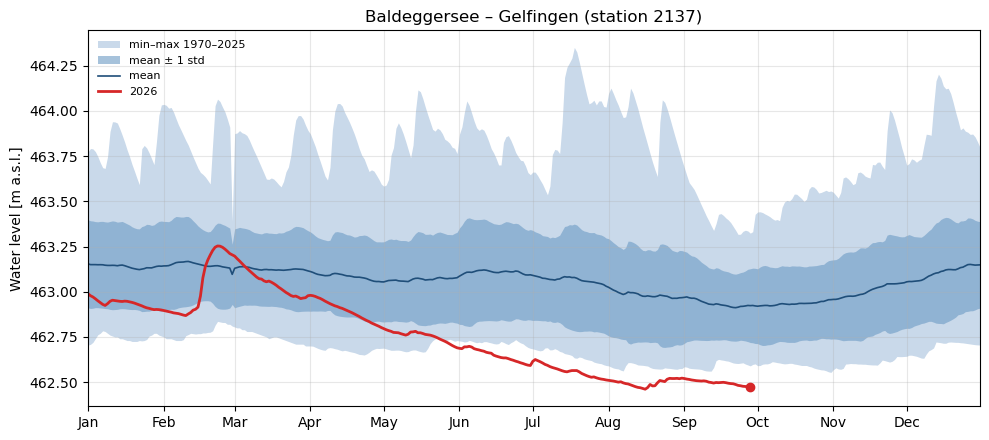

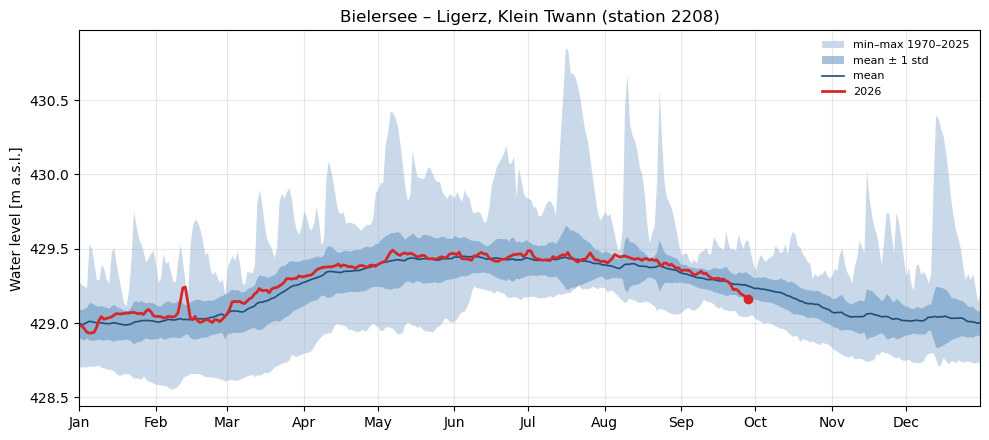

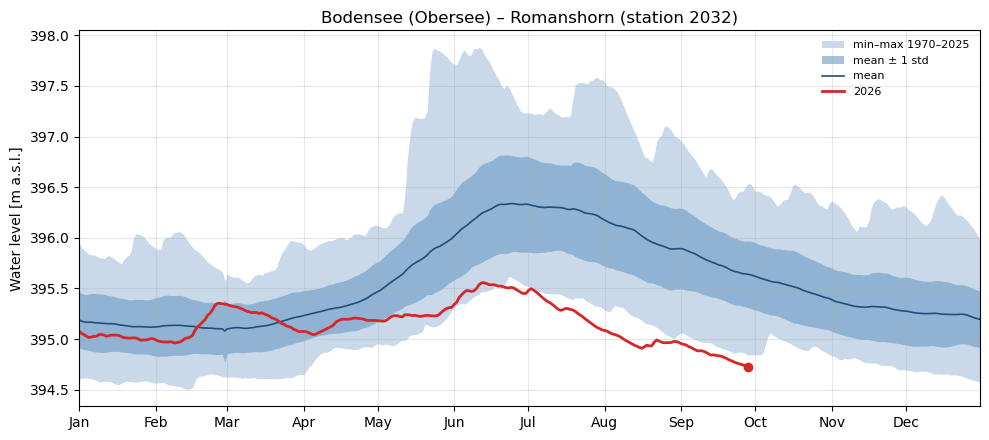

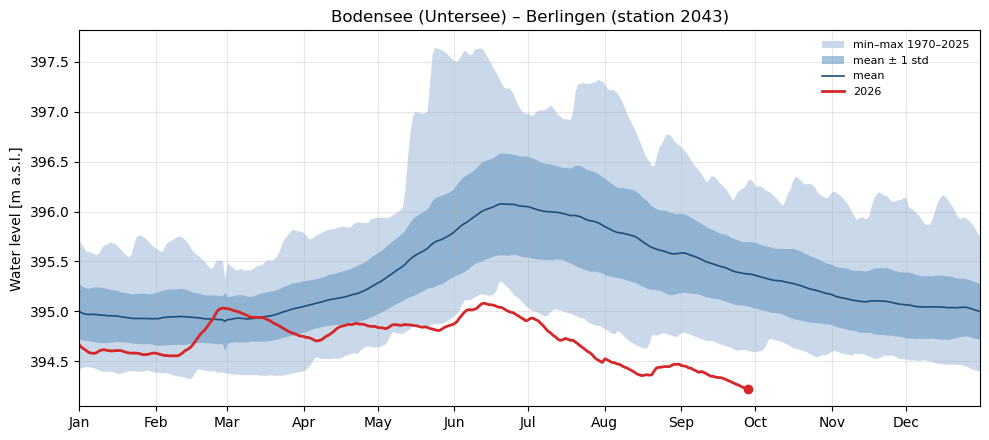

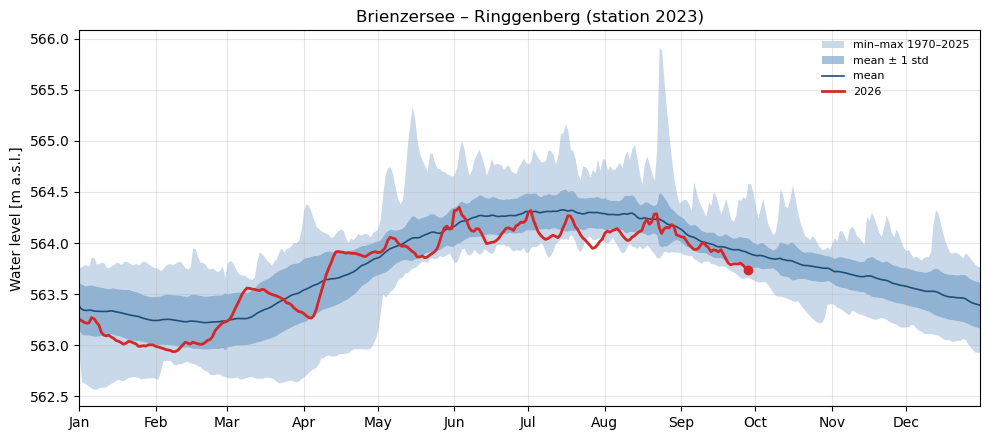

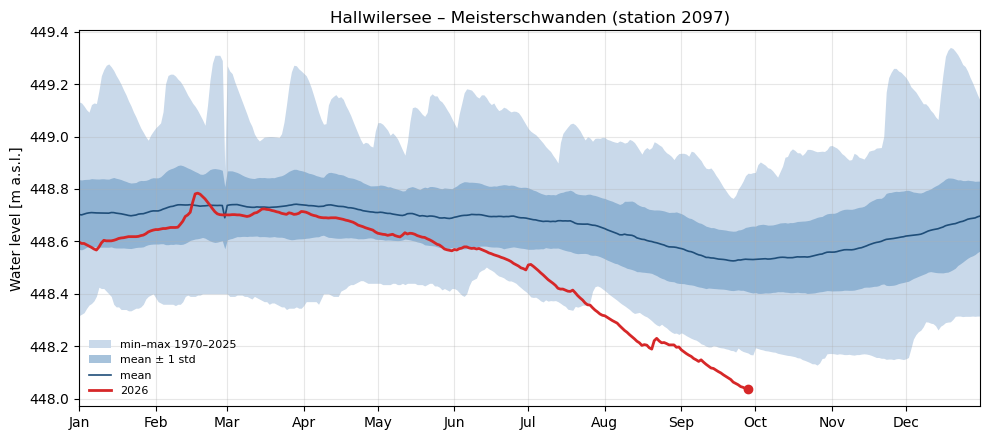

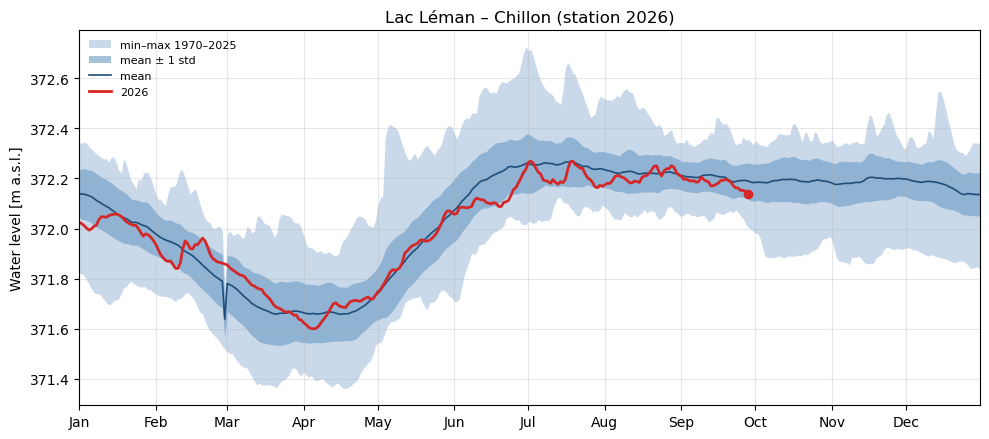

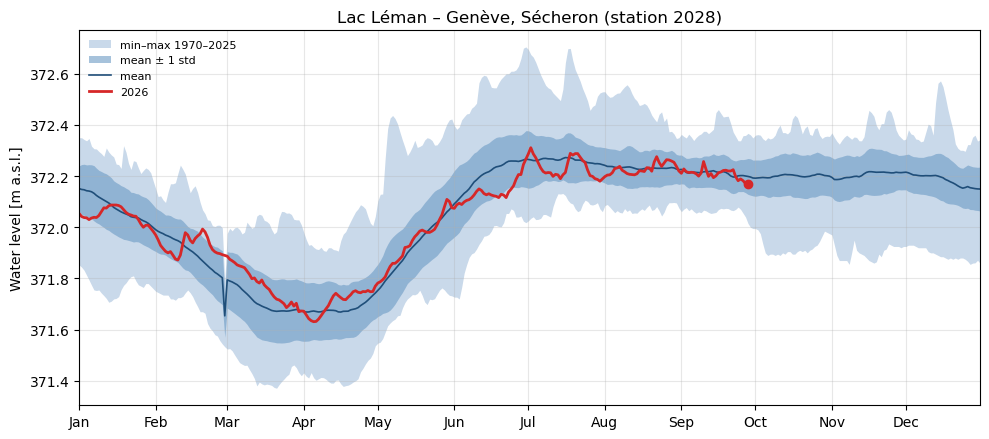

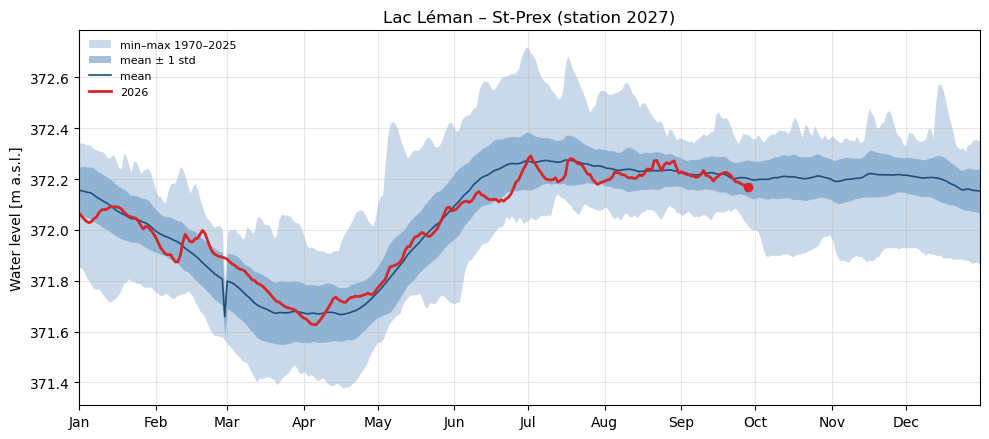

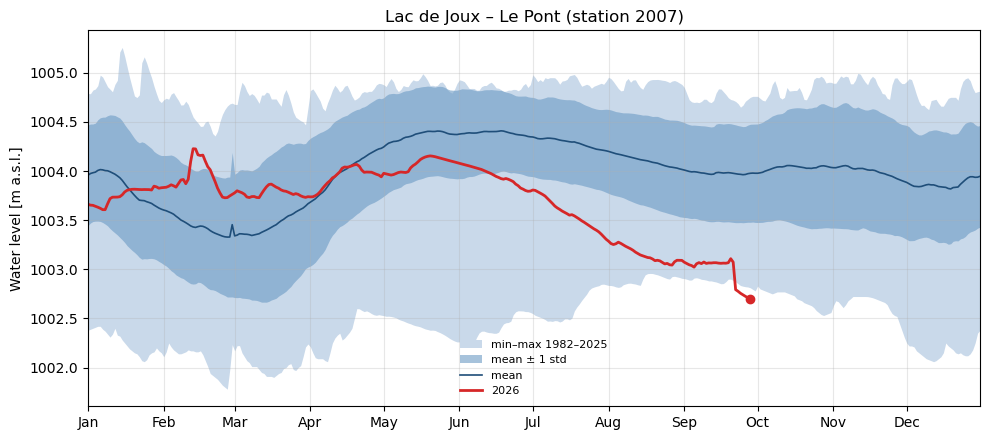

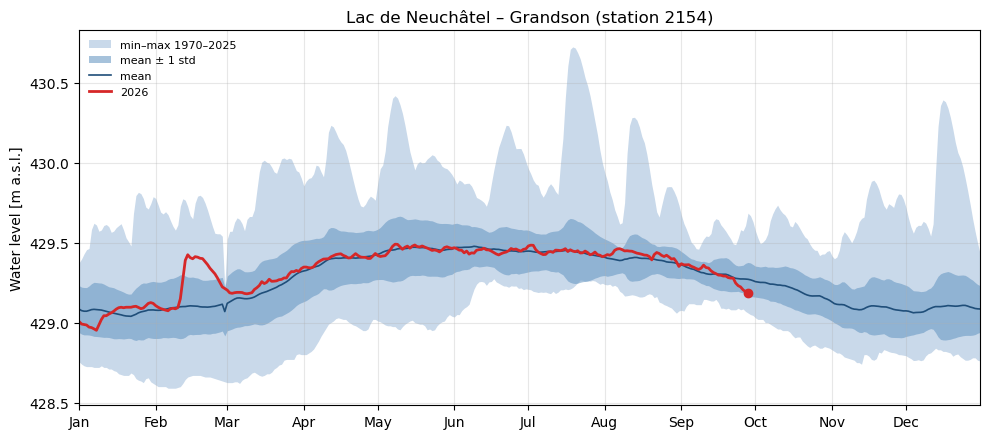

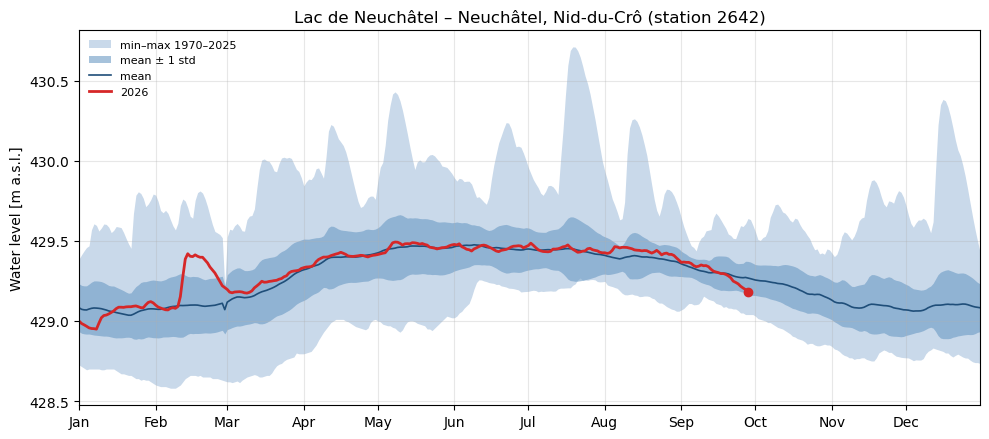

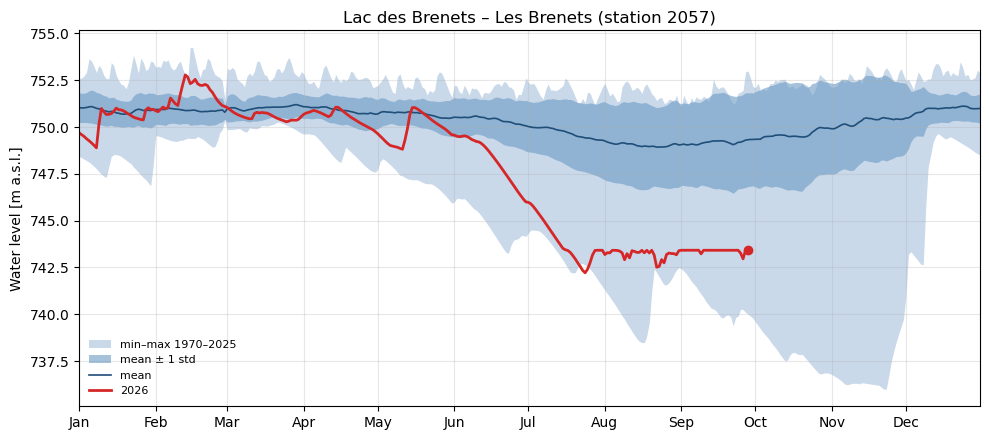

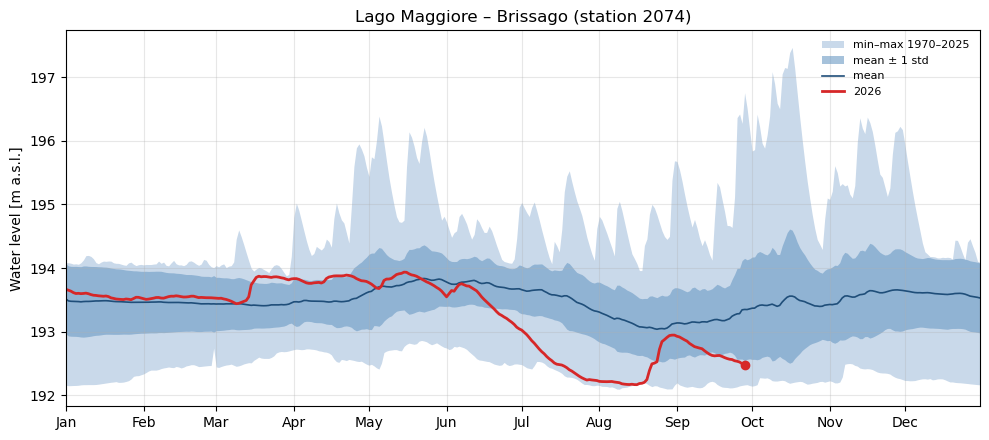

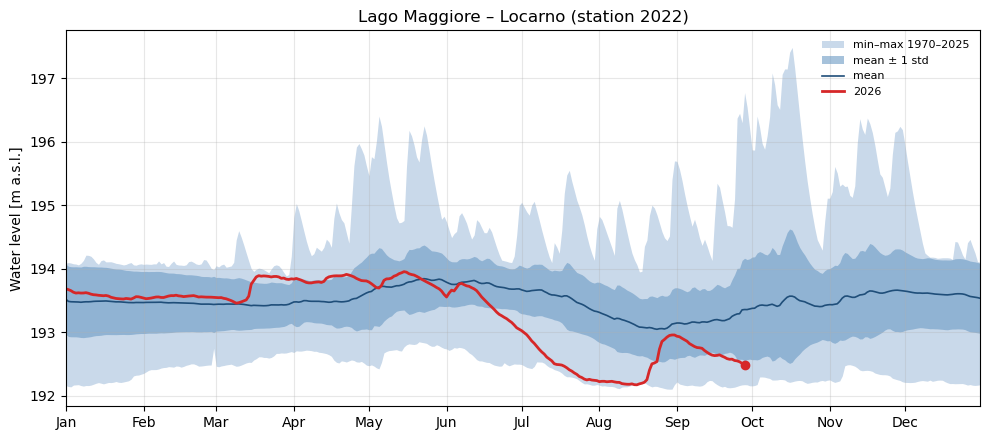

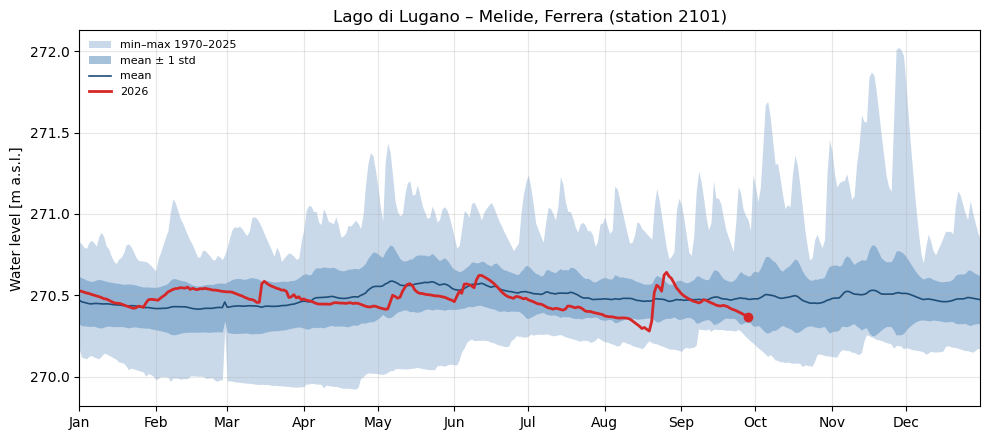

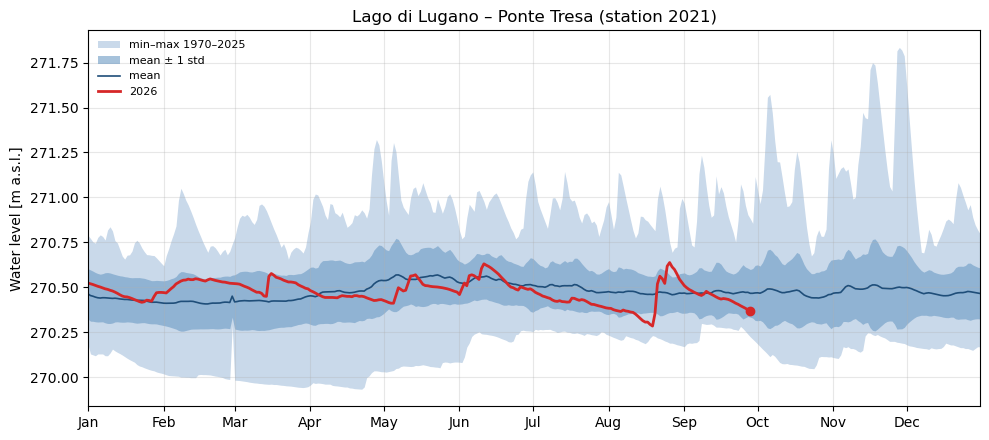

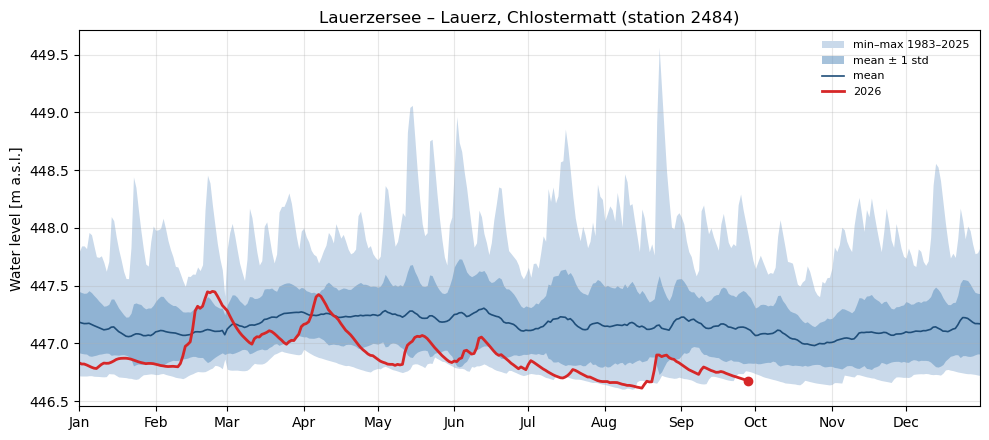

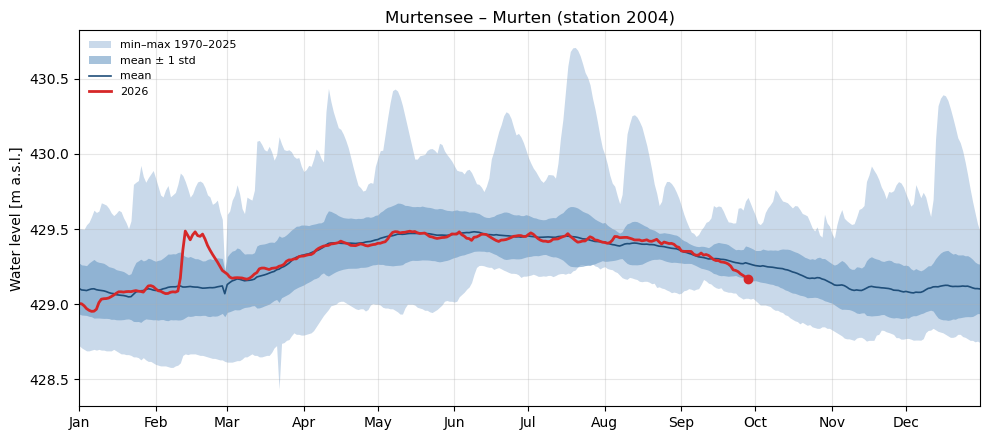

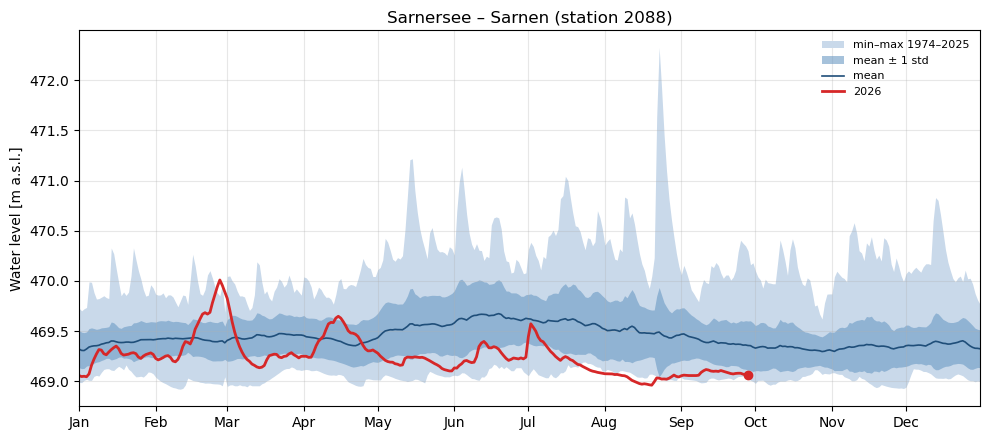

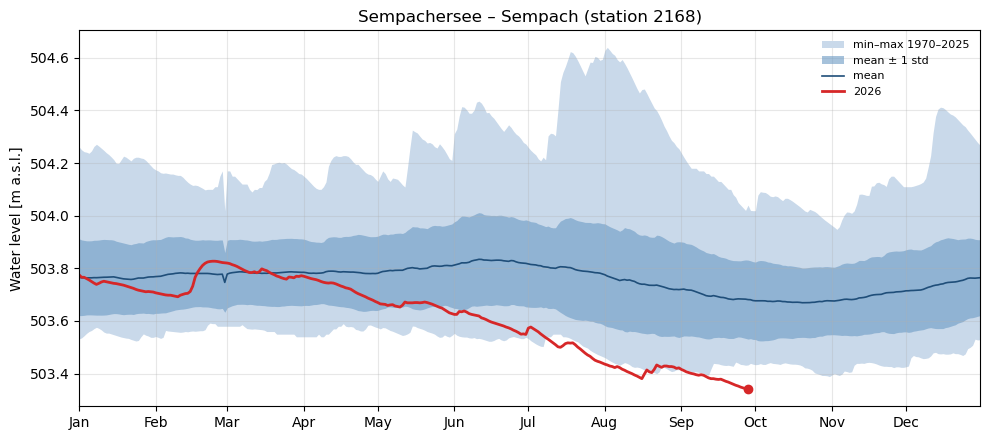

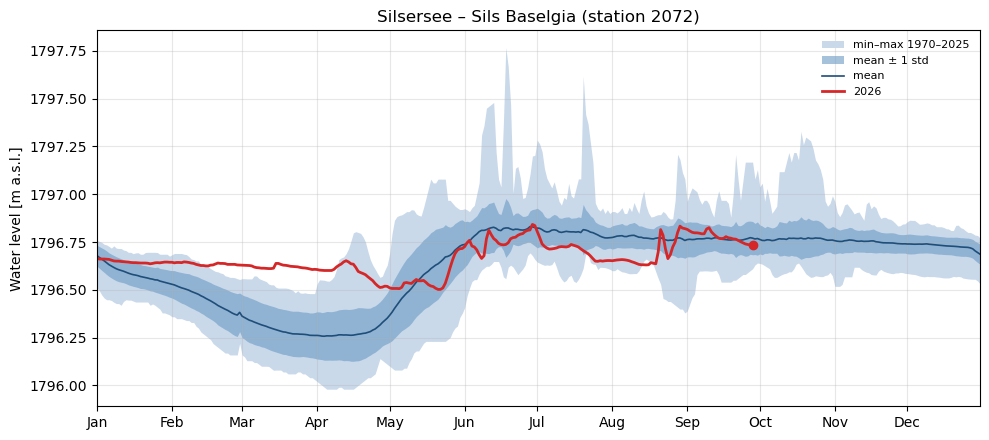

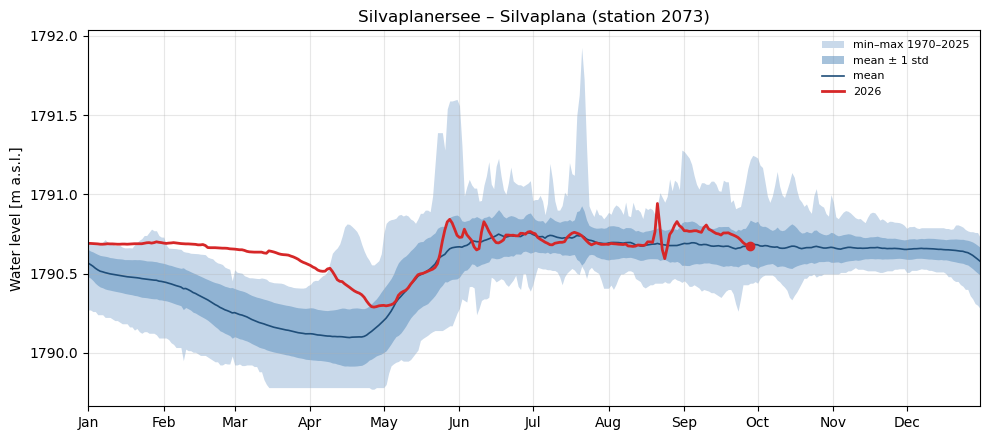

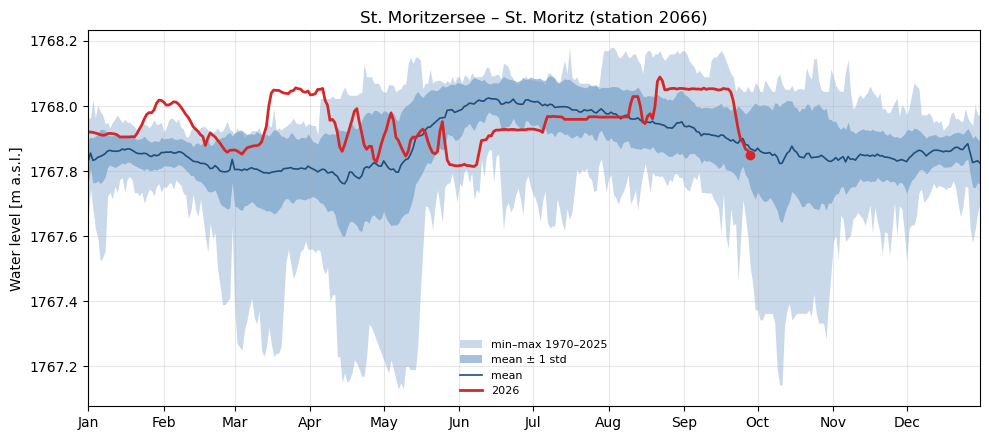

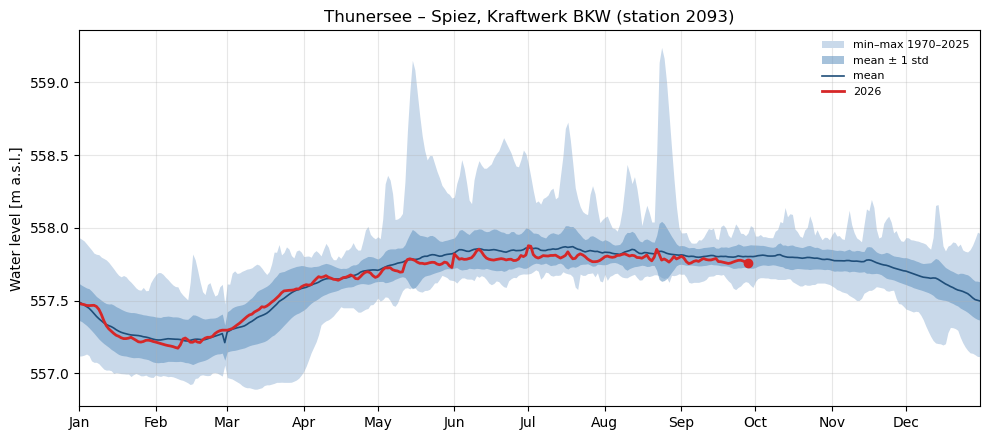

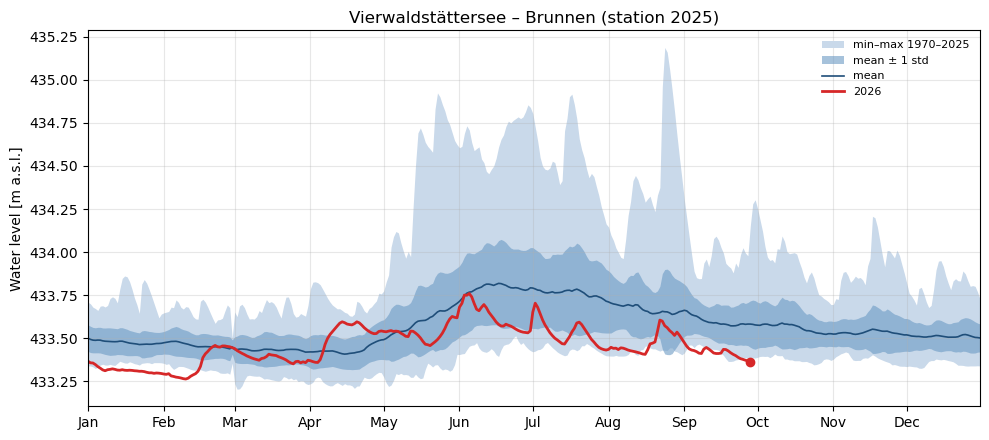

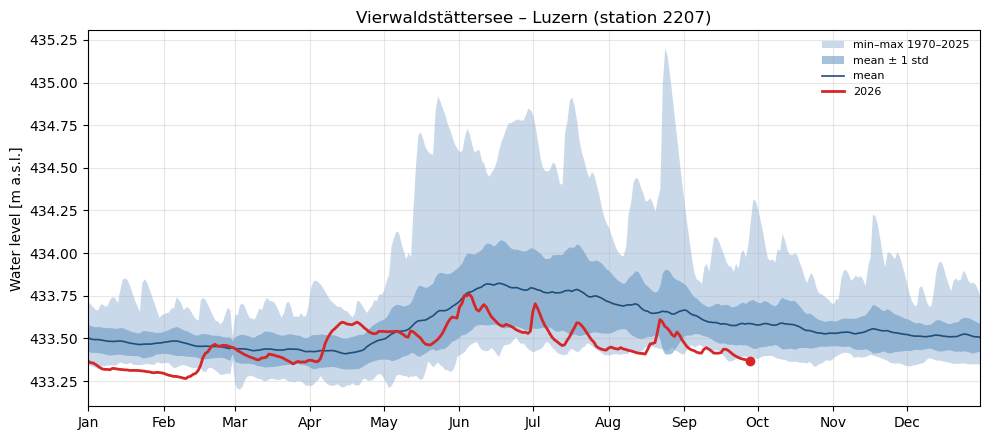

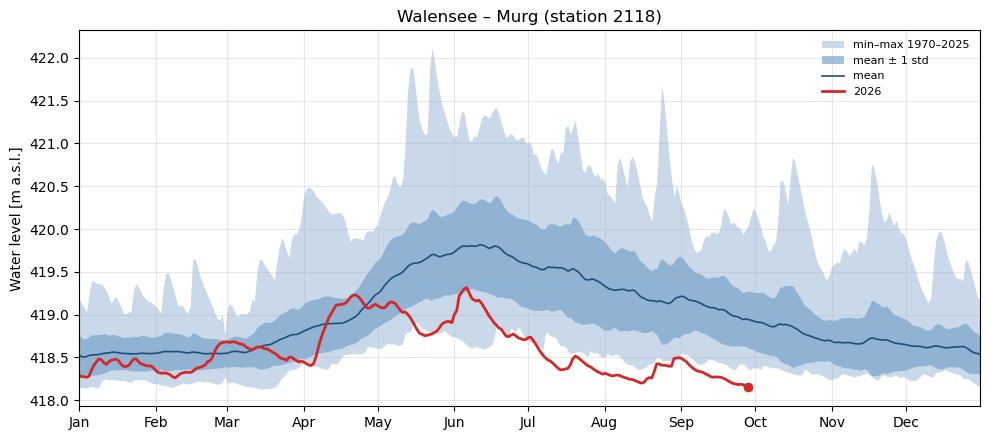

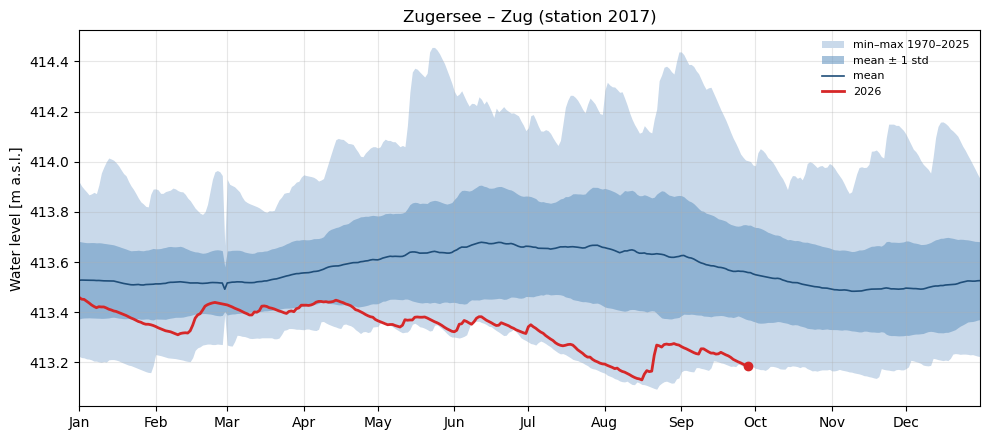

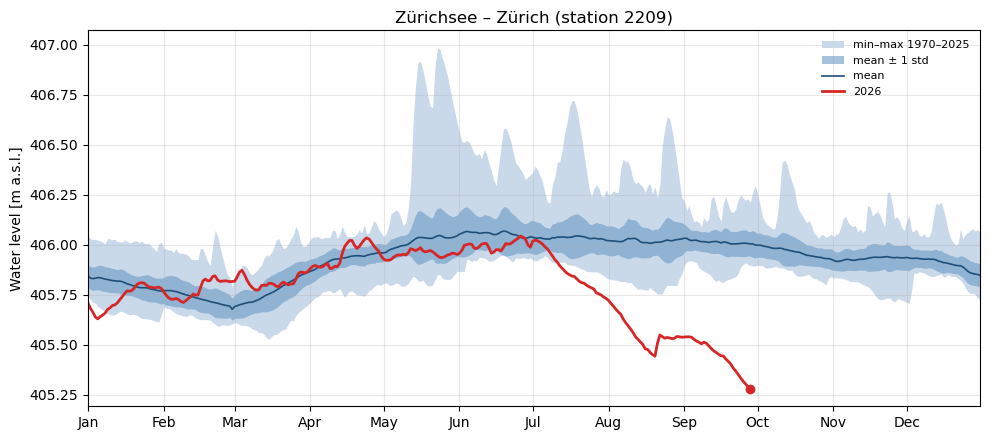

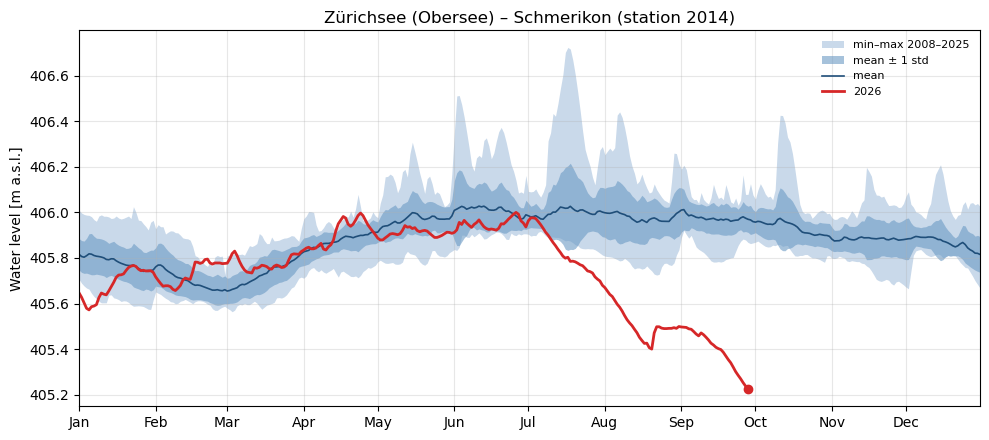

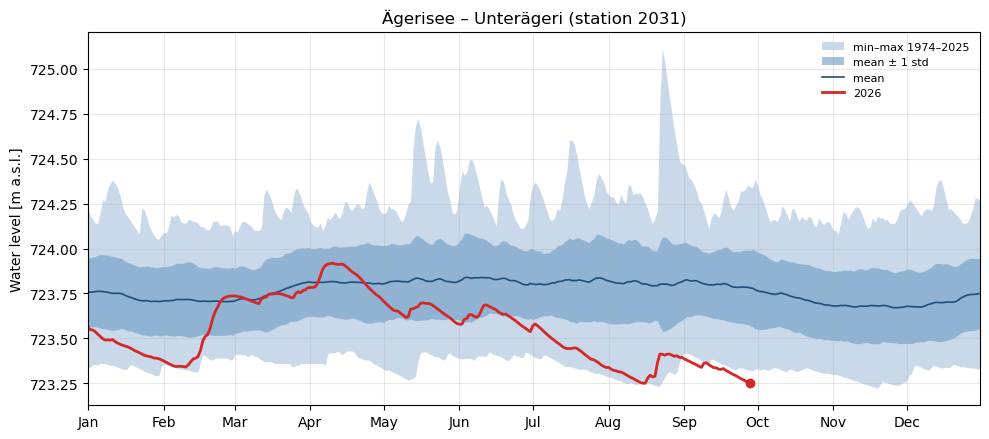

In [7]:
C_CUR, C_MEAN, C_STD, C_RANGE = "#d62728", "#1f4e79", "#6b9ac4", "#c9d9ea"

def plot_station(row, ax, compact=False):
    s = series[row.no]["value"]
    clim, (y0, y1) = clims[row.no]
    if clim is None:
        ax.set_title(f"{row.lake} – {row.name}: no data", fontsize=9)
        return
    x = clim.index
    ax.fill_between(x, clim["min"], clim["max"], color=C_RANGE, lw=0, label=f"min–max {y0}–{y1}")
    ax.fill_between(x, clim["mean"] - clim["std"], clim["mean"] + clim["std"], color=C_STD, alpha=0.6,
                    lw=0, label="mean ± 1 std")
    ax.plot(x, clim["mean"], color=C_MEAN, lw=1.2, label="mean")
    cur = current_year(s)
    if len(cur):
        ax.plot(cur.index, cur.values, color=C_CUR, lw=2 if not compact else 1.4, label=str(CURRENT_YEAR))
        ax.plot(cur.index[-1], cur.values[-1], "o", color=C_CUR, ms=4 if compact else 6)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_xlim(pd.Timestamp(f"{REF_YEAR}-01-01"), pd.Timestamp(f"{REF_YEAR}-12-31"))
    ax.grid(alpha=0.3)
    ax.yaxis.get_major_formatter().set_useOffset(False)
    if compact:
        ax.set_title(f"{row.lake}\n{row.name} ({row.no})", fontsize=8)
        ax.tick_params(labelsize=6)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        for lbl in ax.get_xticklabels():
            lbl.set_rotation(90)
    else:
        ax.set_title(f"{row.lake} – {row.name} (station {row.no})")
        ax.set_ylabel("Water level [m a.s.l.]")
        ax.legend(loc="best", fontsize=8, frameon=False)

for row in lakes.itertuples():
    fig, ax = plt.subplots(figsize=(10, 4.5))
    plot_station(row, ax)
    fig.tight_layout()
    safe = re.sub(r"[^\w]+", "_", f"{row.no}_{row.lake}_{row.name}")
    fig.savefig(FIG_DIR / f"{safe}.png", dpi=150)
    plt.show()

## Overview of all stations

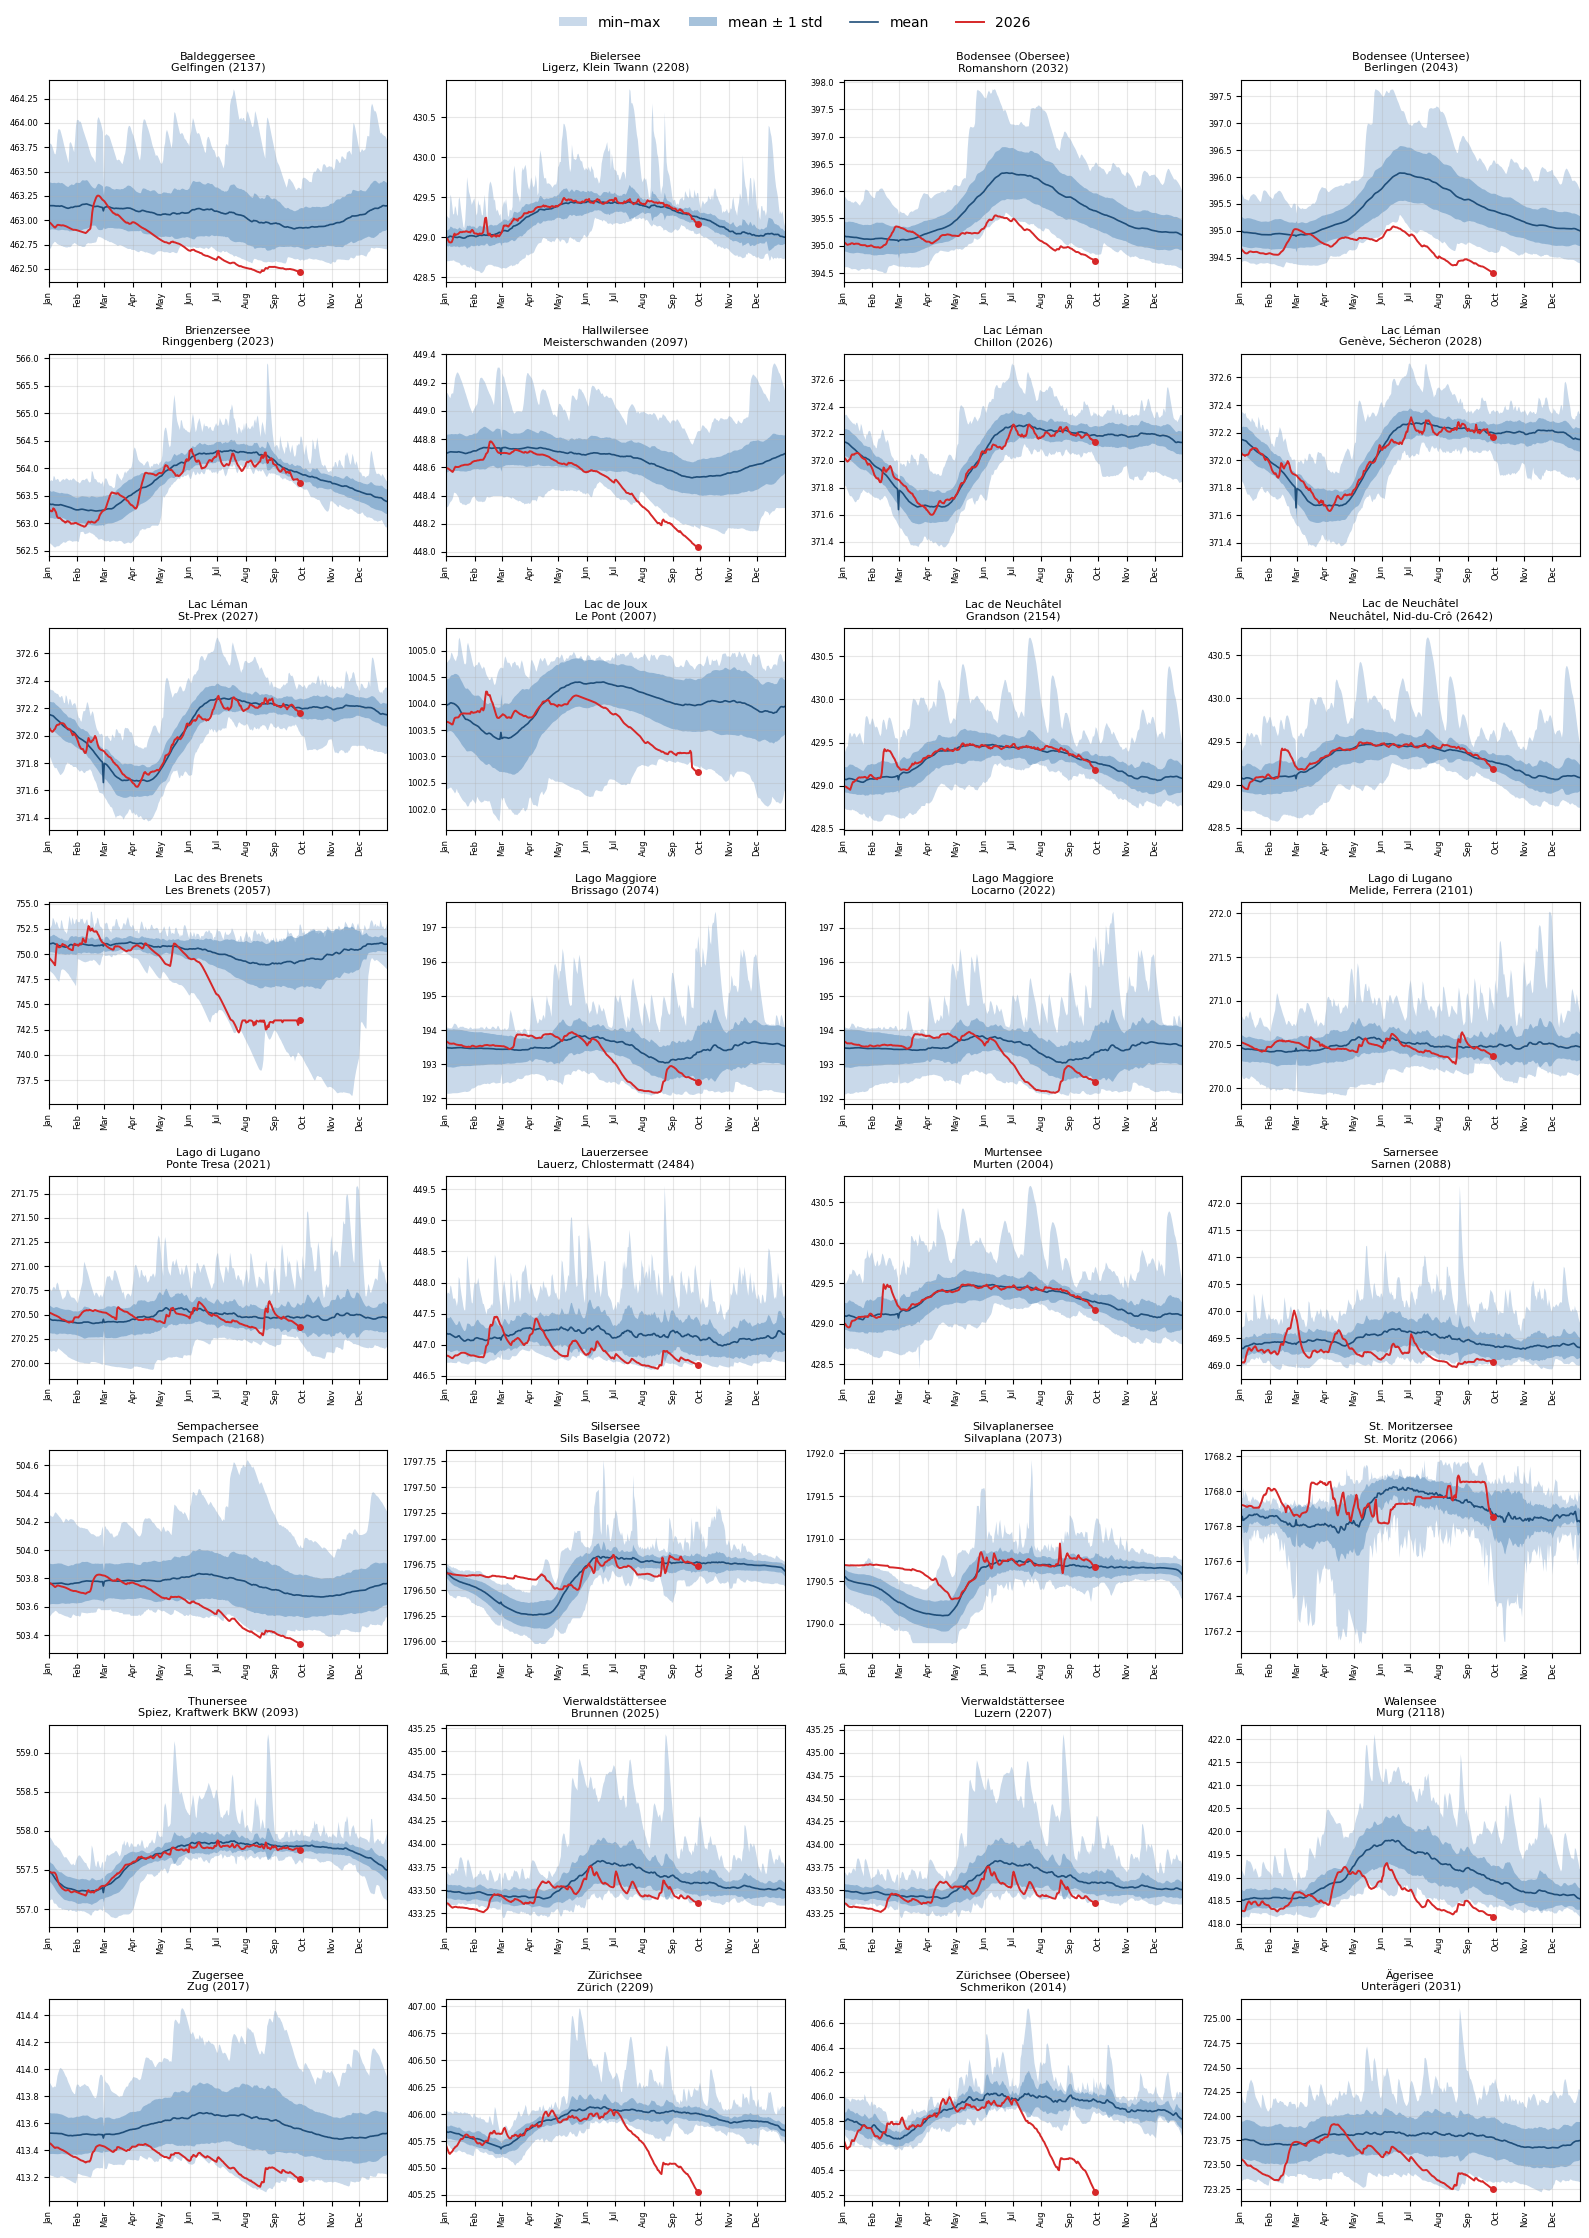

In [8]:
ncol = 4
nrow = int(np.ceil(len(lakes) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.8 * nrow))
for ax, row in zip(axes.flat, lakes.itertuples()):
    plot_station(row, ax, compact=True)
for ax in axes.flat[len(lakes):]:
    ax.remove()
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, ["min–max", "mean ± 1 std", "mean", str(CURRENT_YEAR)], loc="upper center",
           ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.985))
fig.savefig(FIG_DIR / "overview_all_lakes.png", dpi=130)
plt.show()

## Latest value vs. climatology

In [9]:
rows = []
for row in lakes.itertuples():
    s = series[row.no]["value"].dropna()
    clim, _ = clims[row.no]
    if s.empty or clim is None:
        continue
    d, v = s.index[-1], s.iloc[-1]
    c = clim.loc[pd.Timestamp(REF_YEAR, d.month, d.day)]
    rows.append({"no": row.no, "lake": row.lake, "station": row.name, "date": d.date(), "level": v,
                 "clim_mean": c["mean"], "anomaly_cm": 100 * (v - c["mean"]),
                 "z": (v - c["mean"]) / c["std"] if c["std"] > 0 else np.nan,
                 "clim_min": c["min"], "clim_max": c["max"]})
status = pd.DataFrame(rows).round({"level": 3, "clim_mean": 3, "anomaly_cm": 1, "z": 2,
                                   "clim_min": 3, "clim_max": 3})
status.sort_values("z")

,no,lake,station,date,level,clim_mean,anomaly_cm,z,clim_min,clim_max
30,2014,Zürichsee (Obersee),Schmerikon,2026-09-28,405.224,405.970,-74.6,-12.99,405.868,406.079
29,2209,Zürichsee,Zürich,2026-09-28,405.277,406.004,-72.7,-11.89,405.897,406.212
5,2097,Hallwilersee,Meisterschwanden,2026-09-28,448.036,448.531,-49.5,-4.00,448.174,448.860
3,2043,Bodensee (Untersee),Berlingen,2026-09-28,394.220,395.375,-115.5,-3.56,394.608,396.315
2,2032,Bodensee (Obersee),Romanshorn,2026-09-28,394.727,395.640,-91.3,-2.77,394.843,396.537
9,2007,Lac de Joux,Le Pont,2026-09-28,1002.698,1003.977,-127.9,-2.56,1002.812,1004.750
31,2031,Ägerisee,Unterägeri,2026-09-28,723.249,723.780,-53.1,-2.54,723.321,724.343
27,2118,Walensee,Murg,2026-09-28,418.153,418.945,-79.2,-2.41,418.368,420.039
12,2057,Lac des Brenets,Les Brenets,2026-09-28,743.419,749.322,-590.3,-2.36,740.012,752.988
20,2168,Sempachersee,Sempach,2026-09-28,503.341,503.681,-34.0,-2.27,503.433,504.040


## One station per lake

Where a lake has several stations, use the preferred one below, otherwise the station with the longest record.
Separate basins (Bodensee Ober-/Untersee, Zürichsee/Obersee) are kept as separate lakes.

In [10]:
PREFERRED = {"Lac Léman": "2028", "Lago Maggiore": "2022", "Lago di Lugano": "2021",
             "Vierwaldstättersee": "2207", "Lac de Neuchâtel": "2154"}

lakes["n_valid"] = lakes["no"].map(lambda n: series[n]["value"].notna().sum())
picked = []
for lake, g in lakes.groupby("lake"):
    pref = PREFERRED.get(lake)
    picked.append(g[g["no"] == pref].iloc[0] if pref in g["no"].values else g.loc[g["n_valid"].idxmax()])
one = pd.DataFrame(picked).reset_index(drop=True)
one[["lake", "no", "name", "n_valid"]]

,lake,no,name,n_valid
0,Baldeggersee,2137,Gelfingen,20724
1,Bielersee,2208,"Ligerz, Klein Twann",20724
2,Bodensee (Obersee),2032,Romanshorn,20724
3,Bodensee (Untersee),2043,Berlingen,20724
4,Brienzersee,2023,Ringgenberg,20724
5,Hallwilersee,2097,Meisterschwanden,20724
6,Lac Léman,2028,"Genève, Sécheron",20724
7,Lac de Joux,2007,Le Pont,16341
8,Lac de Neuchâtel,2154,Grandson,20724
9,Lac des Brenets,2057,Les Brenets,20724


## Current anomaly per lake (latest day − climatological mean)

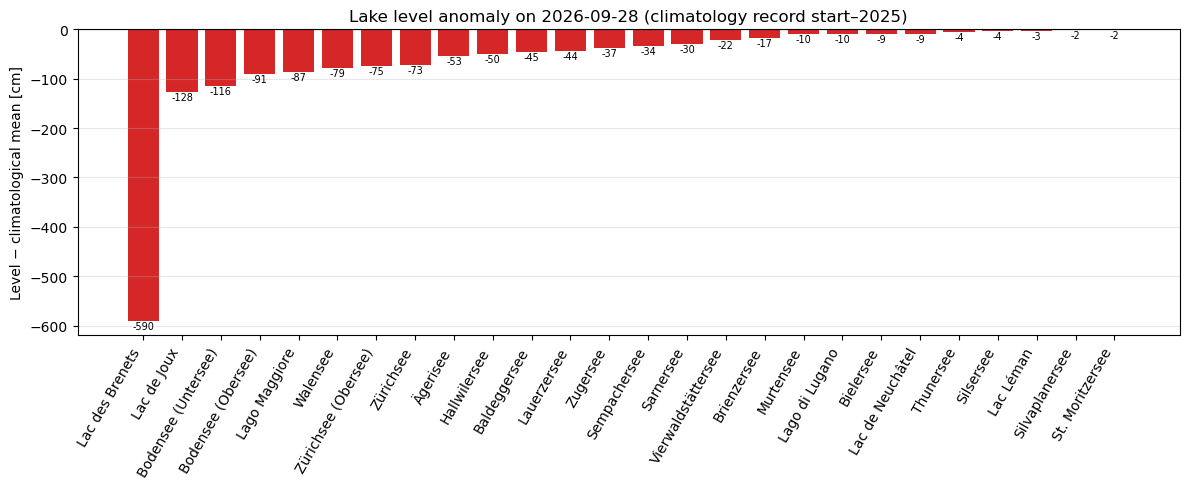

In [11]:
anom = status[status["no"].isin(one["no"])].sort_values("anomaly_cm").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 5))
colors = np.where(anom["anomaly_cm"] < 0, C_CUR, C_MEAN)
ax.bar(anom["lake"], anom["anomaly_cm"], color=colors)
for i, v in enumerate(anom["anomaly_cm"]):
    ax.text(i, v, f"{v:.0f}", ha="center", va="top" if v < 0 else "bottom", fontsize=7)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Level − climatological mean [cm]")
ax.set_title(f"Lake level anomaly on {anom['date'].max()} (climatology {CLIM_START_YEAR or 'record start'}–{CLIM_END_YEAR})")
ax.tick_params(axis="x", rotation=60)
plt.setp(ax.get_xticklabels(), ha="right")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "anomaly_per_lake.png", dpi=150)
plt.show()

## How unusual is this year?

For each lake, the standardised anomaly `(level − mean) / std` on the latest calendar day is shown for
**every year** of the record (grey) and for the current year (red). The label gives the current year's rank
from the lowest (`1/N` = lowest value on this date in N years). Standardising makes lakes with very
different natural ranges comparable; the rank does not depend on any distributional assumption.

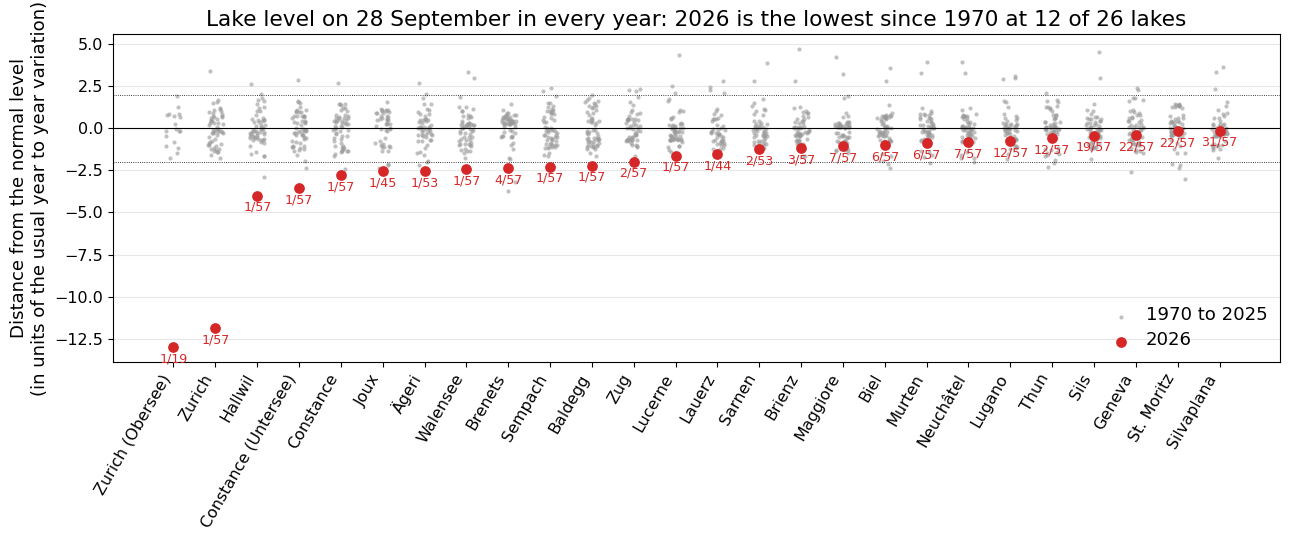

In [12]:
rows = []
for r in one.itertuples():
    s = series[r.no]["value"].dropna()
    clim, _ = clims[r.no]
    d = s.index[-1]
    c = clim.loc[pd.Timestamp(REF_YEAR, d.month, d.day)]
    same_day = s[(s.index.month == d.month) & (s.index.day == d.day)]
    z = (same_day - c["mean"]) / c["std"]
    for ts, zv in z.items():
        rows.append({"lake": r.lake, "year": ts.year, "z": zv})
yz = pd.DataFrame(rows)

cur = yz[yz["year"] == CURRENT_YEAR].set_index("lake")["z"]
rank = yz.groupby("lake")["z"].rank(method="min")[yz["year"] == CURRENT_YEAR]
rank.index = cur.index
n_years = yz.groupby("lake")["year"].nunique()
order = cur.sort_values().index

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(13, 5.5))
for i, lake in enumerate(order):
    past = yz[(yz["lake"] == lake) & (yz["year"] != CURRENT_YEAR)]["z"]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(past)), past, s=9, color="0.6", alpha=0.6, lw=0,
               label="1970 to 2025" if i == 0 else None)
    ax.scatter(i, cur[lake], s=45, color=C_CUR, zorder=3, label=str(CURRENT_YEAR) if i == 0 else None)
    ax.annotate(f"{int(rank[lake])}/{n_years[lake]}", (i, cur[lake]), xytext=(0, -11 if cur[lake] < 0 else 6),
                textcoords="offset points", ha="center", fontsize=7, color=C_CUR)
ax.axhline(0, color="k", lw=0.8)
for y in (-2, 2):
    ax.axhline(y, color="k", lw=0.6, ls=":")
ax.set_xticks(range(len(order)), [EN.get(l, l) for l in order], rotation=60, ha="right")
ax.set_ylabel("Distance from the normal level\n(in units of the usual year to year variation)")
n_low = int((rank == 1).sum())
ax.set_title(f"Lake level on {status['date'].max():%-d %B} in every year: {CURRENT_YEAR} is the lowest since 1970 "
             f"at {n_low} of {len(order)} lakes")
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "unusualness_per_lake.png", dpi=150)
plt.show()

# Why do some lakes drop and others not? Role of glaciers

Hypothesis: glacier melt keeps feeding rivers in hot, dry summers, so lakes with glacierised catchments
are buffered against drought.

Catchment attributes (area, mean elevation, glacier area) come from **CAMELS-CH**
(Höge et al., 2023, *ESSD*, [doi:10.5281/zenodo.15025258](https://doi.org/10.5281/zenodo.15025258)),
which includes the FOEN lake-level gauges themselves. Only the three attribute tables are kept in `data/camels_ch/`;
they are downloaded (~250 MB zip) if missing.

In [13]:
import io
import zipfile
from scipy.stats import spearmanr

CAMELS_DIR = DATA_DIR / "camels_ch"
CAMELS_URL = "https://zenodo.org/api/records/15025258/files/camels_ch.zip/content"
CAMELS_TABLES = ["glacier", "topographic", "humaninfluence"]

if not all((CAMELS_DIR / f"CAMELS_CH_{k}_attributes.csv").exists() for k in CAMELS_TABLES):
    CAMELS_DIR.mkdir(exist_ok=True)
    print("downloading CAMELS-CH (~250 MB) ...")
    z = zipfile.ZipFile(io.BytesIO(requests.get(CAMELS_URL, timeout=1200).content))
    for k in CAMELS_TABLES:
        name = f"camels_ch/static_attributes/CAMELS_CH_{k}_attributes.csv"
        (CAMELS_DIR / Path(name).name).write_bytes(z.read(name))

def read_camels(k, **kw):
    return pd.read_csv(CAMELS_DIR / f"CAMELS_CH_{k}_attributes.csv", comment="#", dtype={"gauge_id": str}, **kw)

camels = (read_camels("topographic", encoding="latin1")[["gauge_id", "area", "elev_mean"]]
          .merge(read_camels("glacier")[["gauge_id", "glac_area"]], on="gauge_id")
          .rename(columns={"area": "catchment_km2"})
          .set_index("gauge_id"))
camels["glacier_pct"] = 100 * camels["glac_area"] / camels["catchment_km2"]
# Lac des Brenets (Doubs, Jura) is not in CAMELS-CH; its catchment has no glaciers
camels.loc["2057", "glacier_pct"] = 0.0

att = one.set_index("lake")[["no"]].join(camels, on="no")
att["z_level"] = cur
att["rank_level"] = rank
att["n_years"] = n_years
att.sort_values("glacier_pct", ascending=False).round(2)

,no,catchment_km2,elev_mean,glac_area,glacier_pct,z_level,rank_level,n_years
lake,,,,,,,,
Brienzersee,2023,1137.4,1940.45,150.42,13.22,-1.16,3.0,57
Lac Léman,2028,8000.3,1658.49,646.80,8.08,-0.39,22.0,57
Thunersee,2093,2451.5,1742.46,187.89,7.66,-0.57,12.0,57
Silsersee,2072,45.8,2330.09,2.53,5.52,-0.43,19.0,57
Silvaplanersee,2073,137.3,2393.72,7.06,5.14,-0.14,31.0,57
St. Moritzersee,2066,171.2,2370.33,7.25,4.24,-0.16,22.0,57
Vierwaldstättersee,2207,2242.7,1504.16,73.61,3.28,-1.61,1.0,57
Bielersee,2208,8236.0,1145.23,190.52,2.31,-1.00,6.0,57
Walensee,2118,1060.8,1580.36,20.90,1.97,-2.41,1.0,57


## Level anomaly vs. glacier cover

A first look using the lake level anomaly (z) of the latest day. Level is affected by regulation, so this is
only indicative – see the inflow reconstruction below.

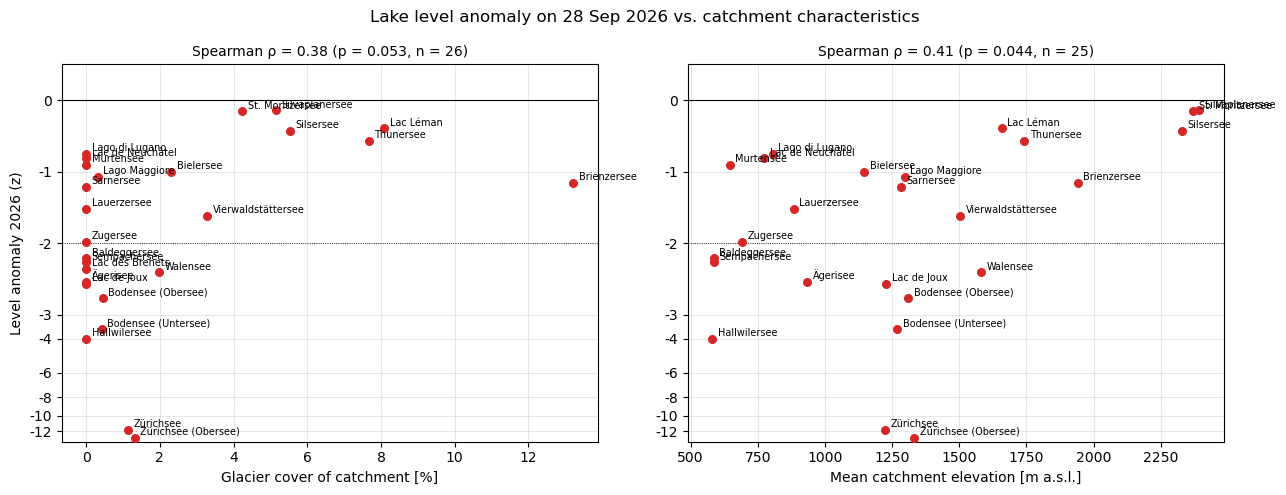

In [14]:
def label_points(ax, x, y, names, fontsize=7):
    for xi, yi, n in zip(x, y, names):
        ax.annotate(n, (xi, yi), xytext=(4, 2), textcoords="offset points", fontsize=fontsize)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, xlabel in [(axes[0], "glacier_pct", "Glacier cover of catchment [%]"),
                        (axes[1], "elev_mean", "Mean catchment elevation [m a.s.l.]")]:
    d = att.dropna(subset=[col, "z_level"])
    ax.scatter(d[col], d["z_level"], color=C_CUR, s=30, zorder=3)
    label_points(ax, d[col], d["z_level"], d.index)
    rho, p = spearmanr(d[col], d["z_level"])
    ax.set_title(f"Spearman ρ = {rho:.2f} (p = {p:.3f}, n = {len(d)})", fontsize=10)
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(-2, color="k", lw=0.6, ls=":")
    ax.set_xlabel(xlabel)
    ax.grid(alpha=0.3)
axes[0].set_ylabel(f"Level anomaly {CURRENT_YEAR} (z)")
axes[0].set_yscale("symlog", linthresh=3)
axes[1].set_yscale("symlog", linthresh=3)
for ax in axes:
    ax.set_yticks([-12, -10, -8, -6, -4, -3, -2, -1, 0])
    ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%g"))
fig.suptitle(f"Lake level anomaly on {status['date'].max():%d %b %Y} vs. catchment characteristics")
fig.tight_layout()
fig.savefig(FIG_DIR / "level_anomaly_vs_glacier.png", dpi=150)
plt.show()

## Inflow reconstruction (removes the effect of regulation)

For a lake system the water balance gives

$$Q_{in} = Q_{out} + \sum_i A_i \, \frac{dH_i}{dt}$$

with the outflow $Q_{out}$ measured at the outlet gauge, $A_i$ the lake surface area and $H_i$ the lake level.
If a weir holds the level constant, the deficit shows up in $Q_{out}$; if the lake is drawn down, it shows up in
$dH/dt$. $Q_{in}$ (total inflow incl. direct precipitation minus evaporation) captures both.

The mean inflow over a summer window (1 July → latest day) is compared across all years.
Lake surface areas are from the FOEN VECTOR25 lake layer (km²). Systems without an FOEN outlet gauge (Lago Maggiore, Lac de Joux,
Hallwiler-, Baldegger-, Ägeri-, Lauerzersee, Lac des Brenets) are not included.

In [15]:
INFLOW_WINDOW_START = (7, 1)   # (month, day) start of the summer window
MIN_COVERAGE = 0.9             # fraction of valid days required per year

# levels: {level station: lake area km², from the FOEN VECTOR25 lake layer}, outflow: {discharge station: sign}, glacier: CAMELS gauge for glacier %
SYSTEMS = {
    "Lac Léman":            dict(levels={"2028": 581.3}, outflow={"2606": 1}, glacier="2028"),
    "Brienzersee":          dict(levels={"2023": 29.8}, outflow={"2457": 1}, glacier="2023"),
    "Thunersee":            dict(levels={"2093": 48.4}, outflow={"2030": 1}, glacier="2093"),
    "Vierwaldstättersee":   dict(levels={"2207": 113.6}, outflow={"2152": 1}, glacier="2207"),
    "Zugersee":             dict(levels={"2017": 38.3}, outflow={"2125": 1}, glacier="2017"),
    "Walensee":             dict(levels={"2118": 24.1}, outflow={"2104": 1}, glacier="2118"),
    # Limmat at Unterhard is below the Sihl confluence -> subtract the Sihl
    "Zürichsee":            dict(levels={"2209": 90.1}, outflow={"2099": 1, "2176": -1}, glacier="2209"),
    "Bodensee":             dict(levels={"2032": 478.3, "2043": 62.9}, outflow={"2288": 1}, glacier="2043"),
    # Sempachersee left out: its summer net inflow is close to zero, so the percentages are not meaningful
    "Sarnersee":            dict(levels={"2088": 7.5}, outflow={"2102": 1}, glacier="2088"),
    "Lago di Lugano":       dict(levels={"2021": 48.7}, outflow={"2167": 1}, glacier="2021"),
    "Jura lakes (Neuchâtel, Biel, Murten)":
                            dict(levels={"2154": 217.9, "2208": 39.8, "2004": 23.0}, outflow={"2029": 1}, glacier="2208"),
    "Upper Engadin lakes (Sils, Silvaplana, St. Moritz)":
                            dict(levels={"2072": 4.1, "2073": 3.2, "2066": 0.78}, outflow={"2105": 1}, glacier="2066"),
}

PARAM_QUERY = """
query ($no: String!, $param: String!, $from: AWSDateTime!, $to: AWSDateTime!) {
  water { observations {
    data_1day_mean(
      where: {station: {no: {_eq: $no}}, parameterName: {_eq: $param},
              timestamp: {_gte: $from, _lt: $to}},
      limit: 10000
    ) { timestamp value }
  } }
}
"""

def load_param(no, param, start=pd.Timestamp("1970-01-01")):
    """Daily mean of `param` at station `no`, cached in data/, returned as a daily Series."""
    path = DATA_DIR / f"{param}_daily_{no}.csv"
    end = pd.Timestamp(datetime.now(timezone.utc)).tz_localize(None) + pd.Timedelta(days=1)
    old = pd.read_csv(path, index_col="date", parse_dates=["date"])["value"] if path.exists() and not REFRESH_ALL else None
    cursor = (old.index.max() - pd.Timedelta(days=30)) if old is not None and len(old) else start
    rows = []
    while cursor < end:
        nxt = min(cursor + pd.DateOffset(years=WINDOW_YEARS), end)
        rows += gql(PARAM_QUERY, {"no": no, "param": param, "from": fmt(cursor), "to": fmt(nxt)})["data_1day_mean"]
        cursor = nxt
    new = pd.Series(dtype=float)
    if rows:
        df = pd.DataFrame(rows)
        df["date"] = (pd.to_datetime(df["timestamp"], utc=True)
                      .dt.tz_convert("Europe/Zurich").dt.tz_localize(None).dt.normalize())
        new = df.set_index("date")["value"]
    s = pd.concat([old, new]) if old is not None else new
    s = s[~s.index.duplicated(keep="last")].sort_index()
    s.index.name = "date"
    s.rename("value").to_frame().to_csv(path)
    return s

q_stations = sorted({no for sys in SYSTEMS.values() for no in sys["outflow"]})
with ThreadPoolExecutor(MAX_WORKERS) as pool:
    Q = dict(zip(q_stations, pool.map(lambda no: load_param(no, "Q"), q_stations)))
if REPORT_END is not None:
    Q = {no: s[:REPORT_END] for no, s in Q.items()}
W = {no: series[no]["value"] for sys in SYSTEMS.values() for no in sys["levels"]}
print("discharge stations:", q_stations)

discharge stations: ['2029', '2030', '2099', '2102', '2104', '2105', '2125', '2152', '2167', '2176', '2288', '2457', '2606']


In [16]:
def daily_inflow(sys):
    idx = pd.date_range("1970-01-01", max(s.index.max() for s in W.values()), freq="D")
    qout = sum(sign * Q[no].reindex(idx) for no, sign in sys["outflow"].items())
    dstore = sum(area * 1e6 * W[no].reindex(idx).diff() for no, area in sys["levels"].items()) / 86400
    return pd.DataFrame({"qin": qout + dstore, "qout": qout, "dstore": dstore})

last_day = min(s.index.max() for s in W.values())
m0, d0 = INFLOW_WINDOW_START

def window_means(df):
    out = {}
    for y in range(df.index.year.min(), CURRENT_YEAR + 1):
        w = df.loc[pd.Timestamp(y, m0, d0):pd.Timestamp(y, last_day.month, last_day.day)]
        n_days = (pd.Timestamp(y, last_day.month, last_day.day) - pd.Timestamp(y, m0, d0)).days + 1
        if w["qin"].notna().sum() >= MIN_COVERAGE * n_days:
            out[y] = w.mean()
    return pd.DataFrame(out).T

inflow_years, rows = {}, []
for name, sys in SYSTEMS.items():
    wm = window_means(daily_inflow(sys))
    inflow_years[name] = wm
    clim = wm.loc[(wm.index >= (CLIM_START_YEAR or 0)) & (wm.index <= CLIM_END_YEAR)]
    if CURRENT_YEAR not in wm.index:
        print(f"{name}: no complete {CURRENT_YEAR} window, skipped")
        continue
    c = wm.loc[CURRENT_YEAR]
    rows.append({"system": name,
                 "glacier_pct": camels.loc[sys["glacier"], "glacier_pct"],
                 "elev_mean": camels.loc[sys["glacier"], "elev_mean"],
                 "qin": c["qin"], "qin_clim": clim["qin"].mean(),
                 "inflow_pct_of_normal": 100 * c["qin"] / clim["qin"].mean(),
                 "outflow_pct_of_normal": 100 * c["qout"] / clim["qout"].mean(),
                 "rank_inflow": int((wm["qin"] <= c["qin"]).sum()), "n_years": len(wm),
                 "first_year": wm.index.min()})
inflow = pd.DataFrame(rows).set_index("system").sort_values("glacier_pct")
print(f"Window: {m0:02d}-{d0:02d} → {last_day:%m-%d}")
inflow.round(1)

Window: 07-01 → 09-28


,glacier_pct,elev_mean,qin,qin_clim,inflow_pct_of_normal,outflow_pct_of_normal,rank_inflow,n_years,first_year
system,,,,,,,,,
Zugersee,0.0,692.5,3.2,8.0,40.2,45.3,4,57,1970
Sarnersee,0.0,1284.0,2.9,10.5,27.4,28.1,1,53,1974
Lago di Lugano,0.0,804.5,8.8,17.4,50.8,54.3,12,57,1970
Bodensee,0.4,1269.0,116.7,412.6,28.3,36.2,1,57,1970
Zürichsee,1.1,1223.4,22.8,99.8,22.8,30.9,1,57,1970
Walensee,2.0,1580.4,19.2,64.0,30.0,31.7,1,57,1970
"Jura lakes (Neuchâtel, Biel, Murten)",2.3,1145.2,142.2,254.2,55.9,58.4,1,57,1970
Vierwaldstättersee,3.3,1504.2,65.0,149.9,43.4,44.2,1,57,1970
"Upper Engadin lakes (Sils, Silvaplana, St. Moritz)",4.2,2370.3,5.3,9.1,58.3,58.9,3,57,1970


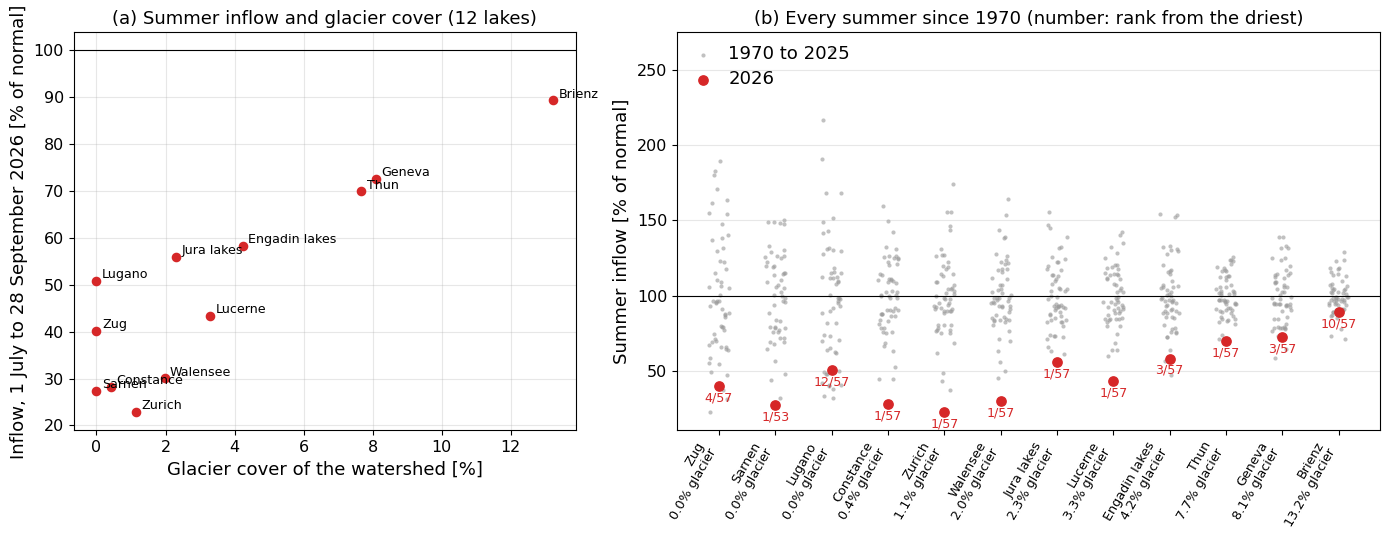

In [17]:
short = lambda n: EN.get(n, n.split(" (")[0])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})

# (a) inflow anomaly vs glacier cover
ax = axes[0]
ax.scatter(inflow["glacier_pct"], inflow["inflow_pct_of_normal"], color=C_CUR, s=35, zorder=3)
label_points(ax, inflow["glacier_pct"], inflow["inflow_pct_of_normal"], [short(n) for n in inflow.index])
rho, p = spearmanr(inflow["glacier_pct"], inflow["inflow_pct_of_normal"])
ax.axhline(100, color="k", lw=0.8)
ax.set_xlabel("Glacier cover of the watershed [%]")
ax.set_ylabel(f"Inflow, {d0} July to {last_day:%-d} September {CURRENT_YEAR} [% of normal]")
ax.set_title(f"(a) Summer inflow and glacier cover ({len(inflow)} lakes)", fontsize=10)
ax.grid(alpha=0.3)

# (b) every year vs current year, systems ordered by glacier cover
ax = axes[1]
rng = np.random.default_rng(0)
for i, name in enumerate(inflow.index):
    wm = inflow_years[name]
    pct = 100 * wm["qin"] / inflow.loc[name, "qin_clim"]
    past = pct[pct.index != CURRENT_YEAR]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(past)), past, s=9, color="0.6", alpha=0.6, lw=0,
               label="1970 to 2025" if i == 0 else None)
    ax.scatter(i, pct[CURRENT_YEAR], s=45, color=C_CUR, zorder=3, label=str(CURRENT_YEAR) if i == 0 else None)
    ax.annotate(f"{inflow.loc[name, 'rank_inflow']}/{inflow.loc[name, 'n_years']}", (i, pct[CURRENT_YEAR]),
                xytext=(0, -11), textcoords="offset points", ha="center", fontsize=7, color=C_CUR)
ax.axhline(100, color="k", lw=0.8)
ax.set_xticks(range(len(inflow)),
              [f"{short(n)}\n{g:.1f}% glacier" for n, g in zip(inflow.index, inflow["glacier_pct"])],
              rotation=60, ha="right", fontsize=8)
ax.set_ylabel("Summer inflow [% of normal]")
ax.set_title("(b) Every summer since 1970 (number: rank from the driest)", fontsize=10)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "inflow_vs_glacier.png", dpi=150)
plt.show()

# SWOT satellite water levels

Water surface elevation (WSE) from the SWOT mission (lake product) in `data/SWOT/*.json`, for smaller Swiss lakes,
reservoirs and a few lakes in neighbouring countries that have no FOEN gauge.

**Important differences to the FOEN gauges**

* SWOT data start in **July 2023**. The reference ("climatology") is therefore only **2023–2025** (2–3 years):
  it shows how 2026 compares with the last few years, **not** whether it is a record.
* Observations are sparse (a few per month), so the reference statistics pool all reference observations within
  ±15 days of each calendar day instead of using single days.
* Quality control: only `qa == "used"` and `wse_u` ≤ 10 cm are kept.
* Some files were matched to a neighbouring lake by the download (large `match_dist_km`, identical series to another
  file). Files matched more than 5 km away, with `lake_name == "no_data"`, or duplicating another file's SWOT lake
  are dropped.
* Heights are converted to the national datum with `H = wse + geoid_hght − separation_m` (m a.s.l., LN02 for
  Switzerland) where a separation is available; otherwise they stay in EGM2008. Anomalies do not depend on the datum.

In [18]:
import json
import warnings

SWOT_DIR = DATA_DIR / "SWOT"
ref_days = lambda idx: pd.DatetimeIndex(to_ref_year(idx))
SWOT_FIG_DIR = FIG_DIR / "swot"
SWOT_FIG_DIR.mkdir(exist_ok=True)

SWOT_MAX_UNC = 0.10       # m, max wse uncertainty
SWOT_MAX_MATCH_KM = 5.0   # max distance between requested lake and matched SWOT lake
SWOT_WINDOW_DAYS = 15     # half-width of the calendar window for reference statistics
SWOT_MIN_YEARS = 2        # reference years required within the window
RESERVOIR_RANGE_M = 2.0   # 5–95 % range of all observations above which a lake is treated as reservoir-like
SWOT_MIN_OBS = 10         # lakes with fewer valid observations are skipped

swot_meta = json.loads((SWOT_DIR / "metadata.json").read_text())

records, dropped = [], []
for path in sorted(SWOT_DIR.glob("*.json")):
    if path.name == "metadata.json":
        continue
    d = json.loads(path.read_text())
    meta = swot_meta.get(d["key"], {})
    country, off = next(((c, o) for c, o in d["offsets"].items() if o.get("separation_m") is not None),
                        (next(iter(d["offsets"]), "?"), {}))
    df = pd.DataFrame(d["data"])
    df["time"] = pd.to_datetime(df["time"], utc=True).dt.tz_convert("Europe/Zurich").dt.tz_localize(None)
    df = df[(df["qa"] == "used") & (df["wse_u"] <= SWOT_MAX_UNC)].copy()
    if off.get("separation_m") is not None:
        df["h"] = df["wse"] + df["geoid_hght"] - off["separation_m"]
        datum = off["datum"]
    else:
        df["h"] = df["wse"]
        datum = "EGM2008"
    records.append(dict(key=d["key"], name=d["name"]["EN"], country="/".join(d["offsets"]), datum=datum,
                        swot_lake_id=meta.get("lake_id"), swot_lake_name=meta.get("lake_name"),
                        area_km2=meta.get("p_ref_area"), match_km=meta.get("match_dist_km"),
                        n_obs=len(df), data=df.set_index("time")["h"].sort_index()))

swot = pd.DataFrame(records)
bad = (swot["match_km"] > SWOT_MAX_MATCH_KM) | (swot["swot_lake_name"] == "no_data")
# several requested lakes resolved to the same SWOT lake: keep the closest match only
dup = swot.sort_values("match_km").duplicated("swot_lake_id").reindex(swot.index)
swot_dropped = swot[bad | dup]
few = swot["n_obs"] < SWOT_MIN_OBS
swot = swot[~(bad | dup | few)].reset_index(drop=True)
print(f"{int((few & ~bad & ~dup).sum())} lakes skipped with < {SWOT_MIN_OBS} valid observations")
print(f"{len(swot)} SWOT lakes kept, {len(swot_dropped)} dropped (mismatched / duplicate):")
print(", ".join(f"{r.name} -> {r.swot_lake_name.split(';')[0]}" for r in swot_dropped.itertuples()))

5 lakes skipped with < 10 valid observations
85 SWOT lakes kept, 15 dropped (mismatched / duplicate):
Étang Avale -> ARNENSEE, Bichelsee -> NUSSBAUMERSEE, Lai da Curnera -> LAI DA NALPS, Favergesee -> DAUBENSEE, Hasensee Ost -> NUSSBAUMERSEE, Lago di Lei -> LEJ DA SEGL, Lac de Lessoc -> LAC DE MONTSALVENS, Oberer Murgsee -> VORALPSEE, Stauweiher Spiez -> no_data, Sufnersee -> LAI DA MARMORERA, Lac des Taillères -> no_data, Triftsee -> GELMERSEE, Lac du Vernex -> ARNENSEE, Étang de Versvey -> ARNENSEE, Wichelsee -> BANNALPSEE


## Check against a FOEN gauge

The file `lei.json` (Lago di Lei) was in fact matched to **Lej da Segl / Silsersee**, which has a FOEN gauge (2072).
This gives an independent check of the SWOT heights and of the datum conversion.

n = 25, bias = 0.4 cm, RMSE = 2.2 cm, std = 2.2 cm


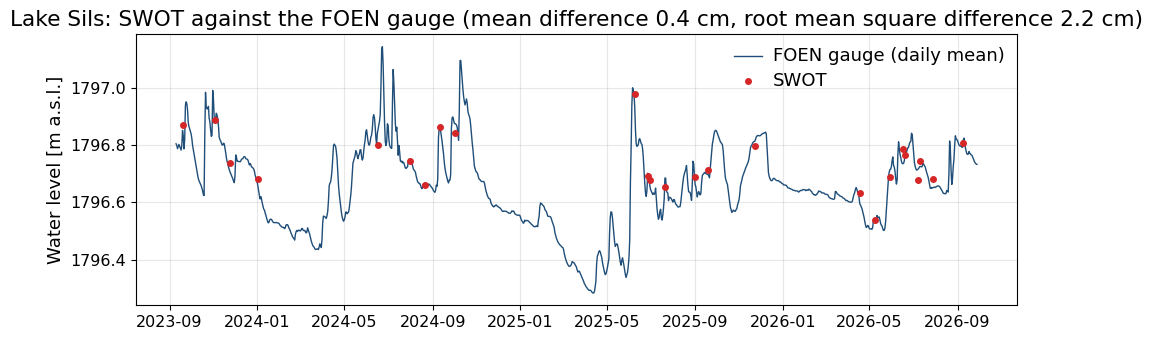

In [19]:
lei = next(r for r in records if r["key"] == "lei")
sat = lei["data"]
gauge = series["2072"]["value"]
cmp = pd.DataFrame({"swot": sat.values, "gauge": gauge.reindex(sat.index.normalize()).values},
                   index=sat.index).dropna()
diff = cmp["swot"] - cmp["gauge"]
print(f"n = {len(cmp)}, bias = {100 * diff.mean():.1f} cm, RMSE = {100 * np.sqrt((diff ** 2).mean()):.1f} cm, "
      f"std = {100 * diff.std():.1f} cm")

fig, ax = plt.subplots(figsize=(10, 3.5))
g = gauge[sat.index.min() - pd.Timedelta(days=10):]
ax.plot(g.index, g.values, color=C_MEAN, lw=1, label="FOEN gauge (daily mean)")
ax.plot(cmp.index, cmp["swot"], "o", color=C_CUR, ms=4, label="SWOT")
ax.set_ylabel("Water level [m a.s.l.]")
ax.set_title(f"Lake Sils: SWOT against the FOEN gauge (mean difference {100 * diff.mean():.1f} cm, "
             f"root mean square difference {100 * np.sqrt((diff ** 2).mean()):.1f} cm)")
ax.yaxis.get_major_formatter().set_useOffset(False)
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(SWOT_FIG_DIR / "validation_silsersee.png", dpi=150)
plt.show()

## Reference statistics 2023–2025 and current year

In [20]:
DOY_GRID = pd.date_range(f"{REF_YEAR}-01-01", f"{REF_YEAR}-12-31", freq="D")

def swot_climatology(s):
    """Stats of reference-period observations within ±SWOT_WINDOW_DAYS of each calendar day."""
    ref = s[s.index.year < CURRENT_YEAR]
    if ref.empty:
        return None
    obs_doy = ref_days(ref.index).dayofyear.values
    grid_doy = DOY_GRID.dayofyear.values
    dist = np.abs(grid_doy[:, None] - obs_doy[None, :])
    dist = np.minimum(dist, 366 - dist)
    inwin = dist <= SWOT_WINDOW_DAYS
    vals = np.where(inwin, ref.values[None, :], np.nan)
    years = ref.index.year.values
    n_years = np.array([len(set(years[m])) for m in inwin])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        clim = pd.DataFrame({"mean": np.nanmean(vals, 1), "std": np.nanstd(vals, 1, ddof=1),
                             "min": np.nanmin(vals, 1), "max": np.nanmax(vals, 1),
                             "n": inwin.sum(1), "n_years": n_years}, index=DOY_GRID)
    clim.loc[clim["n_years"] < SWOT_MIN_YEARS, ["mean", "std", "min", "max"]] = np.nan
    return clim

swot["clim"] = swot["data"].map(swot_climatology)
swot["obs_range"] = swot["data"].map(lambda s: s.quantile(0.95) - s.quantile(0.05))
swot["type"] = np.where(swot["obs_range"] > RESERVOIR_RANGE_M, "reservoir-like", "lake")
print(swot["type"].value_counts().to_string())
swot[["name", "country", "datum", "area_km2", "n_obs", "obs_range", "type"]].round(2)

type
lake              51
reservoir-like    34


,name,country,datum,area_km2,n_obs,obs_range,type
0,Amsoldingersee,CH,LN02,0.32,17,0.39,lake
1,Lake Annecy,FR,NGF-IGN69,26.31,34,0.70,lake
2,Arendsee,DE,DHHN2016,4.79,52,0.68,lake
3,Attersee,AT,GHA,46.02,112,0.53,lake
4,Bannalpsee,CH,LN02,0.11,20,5.44,reservoir-like
...,...,...,...,...,...,...,...
80,Wallersee,AT,GHA,5.61,42,0.82,lake
81,Lake Wohlen,CH,LN02,2.30,56,0.39,lake
82,Lake Wolfgang,AT,GHA,12.71,95,0.58,lake
83,Wörthersee,AT,GHA,18.97,73,0.60,lake


In [21]:
def plot_swot(r, ax, compact=False):
    s, clim = r.data, r.clim
    ref = s[s.index.year < CURRENT_YEAR]
    cur_s = s[s.index.year == CURRENT_YEAR]
    y0, y1 = ref.index.year.min(), ref.index.year.max()
    if clim is not None:
        ax.fill_between(clim.index, clim["min"], clim["max"], color=C_RANGE, lw=0, label=f"min–max {y0}–{y1}")
        ax.fill_between(clim.index, clim["mean"] - clim["std"], clim["mean"] + clim["std"], color=C_STD,
                        alpha=0.6, lw=0, label="mean ± 1 std")
        ax.plot(clim.index, clim["mean"], color=C_MEAN, lw=1.2, label="mean")
    ax.plot(ref_days(ref.index), ref.values, "o", color="0.45", ms=2 if compact else 3, alpha=0.7,
            label=f"SWOT {y0}–{y1}")
    if len(cur_s):
        ax.plot(ref_days(cur_s.index), cur_s.values, "-o", color=C_CUR, lw=1.2 if compact else 1.8,
                ms=2.5 if compact else 4, label=str(CURRENT_YEAR))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_xlim(pd.Timestamp(f"{REF_YEAR}-01-01"), pd.Timestamp(f"{REF_YEAR}-12-31"))
    ax.yaxis.get_major_formatter().set_useOffset(False)
    ax.grid(alpha=0.3)
    if compact:
        ax.set_title(f"{r.name} ({r.country})", fontsize=8)
        ax.tick_params(labelsize=6)
        for lbl in ax.get_xticklabels():
            lbl.set_rotation(90)
    else:
        ax.set_title(f"{r.name} ({r.country}) – SWOT, {r.type}")
        ax.set_ylabel(f"Water level [m, {r.datum}]")
        ax.legend(loc="best", fontsize=8, frameon=False)

# one figure per lake, saved only (too many to display)
for r in swot.itertuples():
    fig, ax = plt.subplots(figsize=(10, 4.5))
    plot_swot(r, ax)
    fig.tight_layout()
    fig.savefig(SWOT_FIG_DIR / f"{r.key}.png", dpi=150)
    plt.close(fig)
print(f"saved {len(swot)} figures to {SWOT_FIG_DIR}")

saved 85 figures to figures/swot


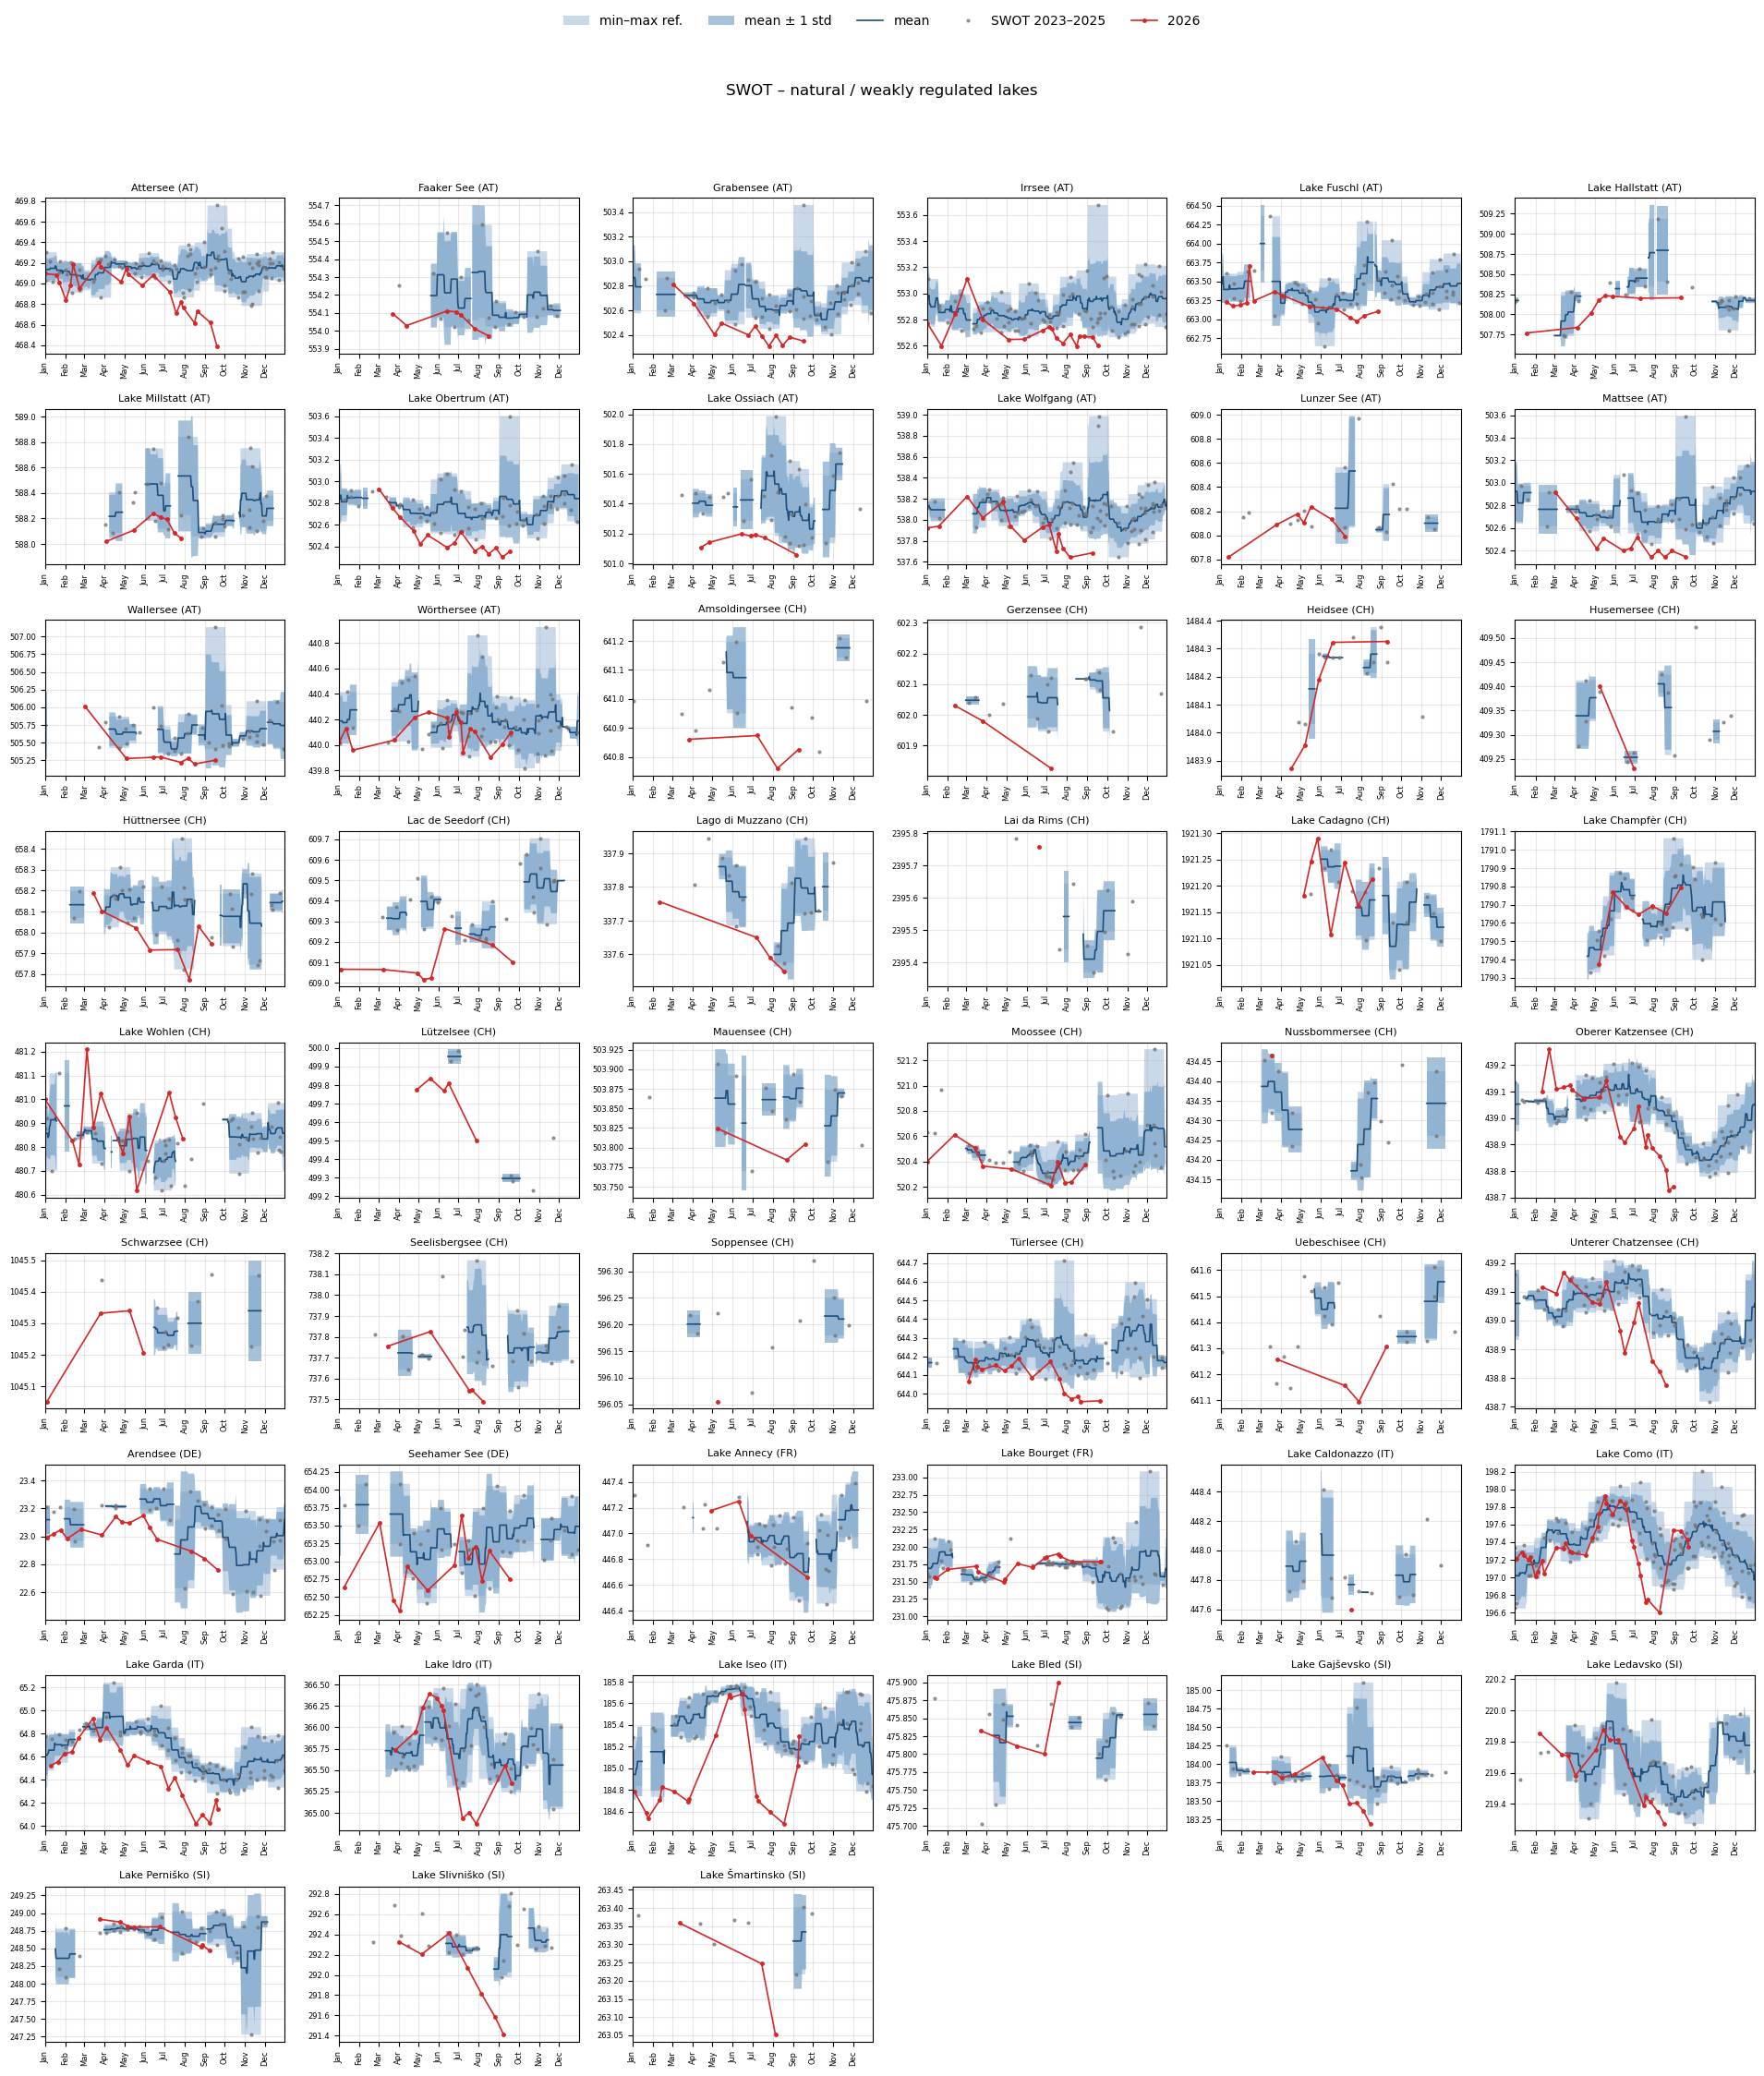

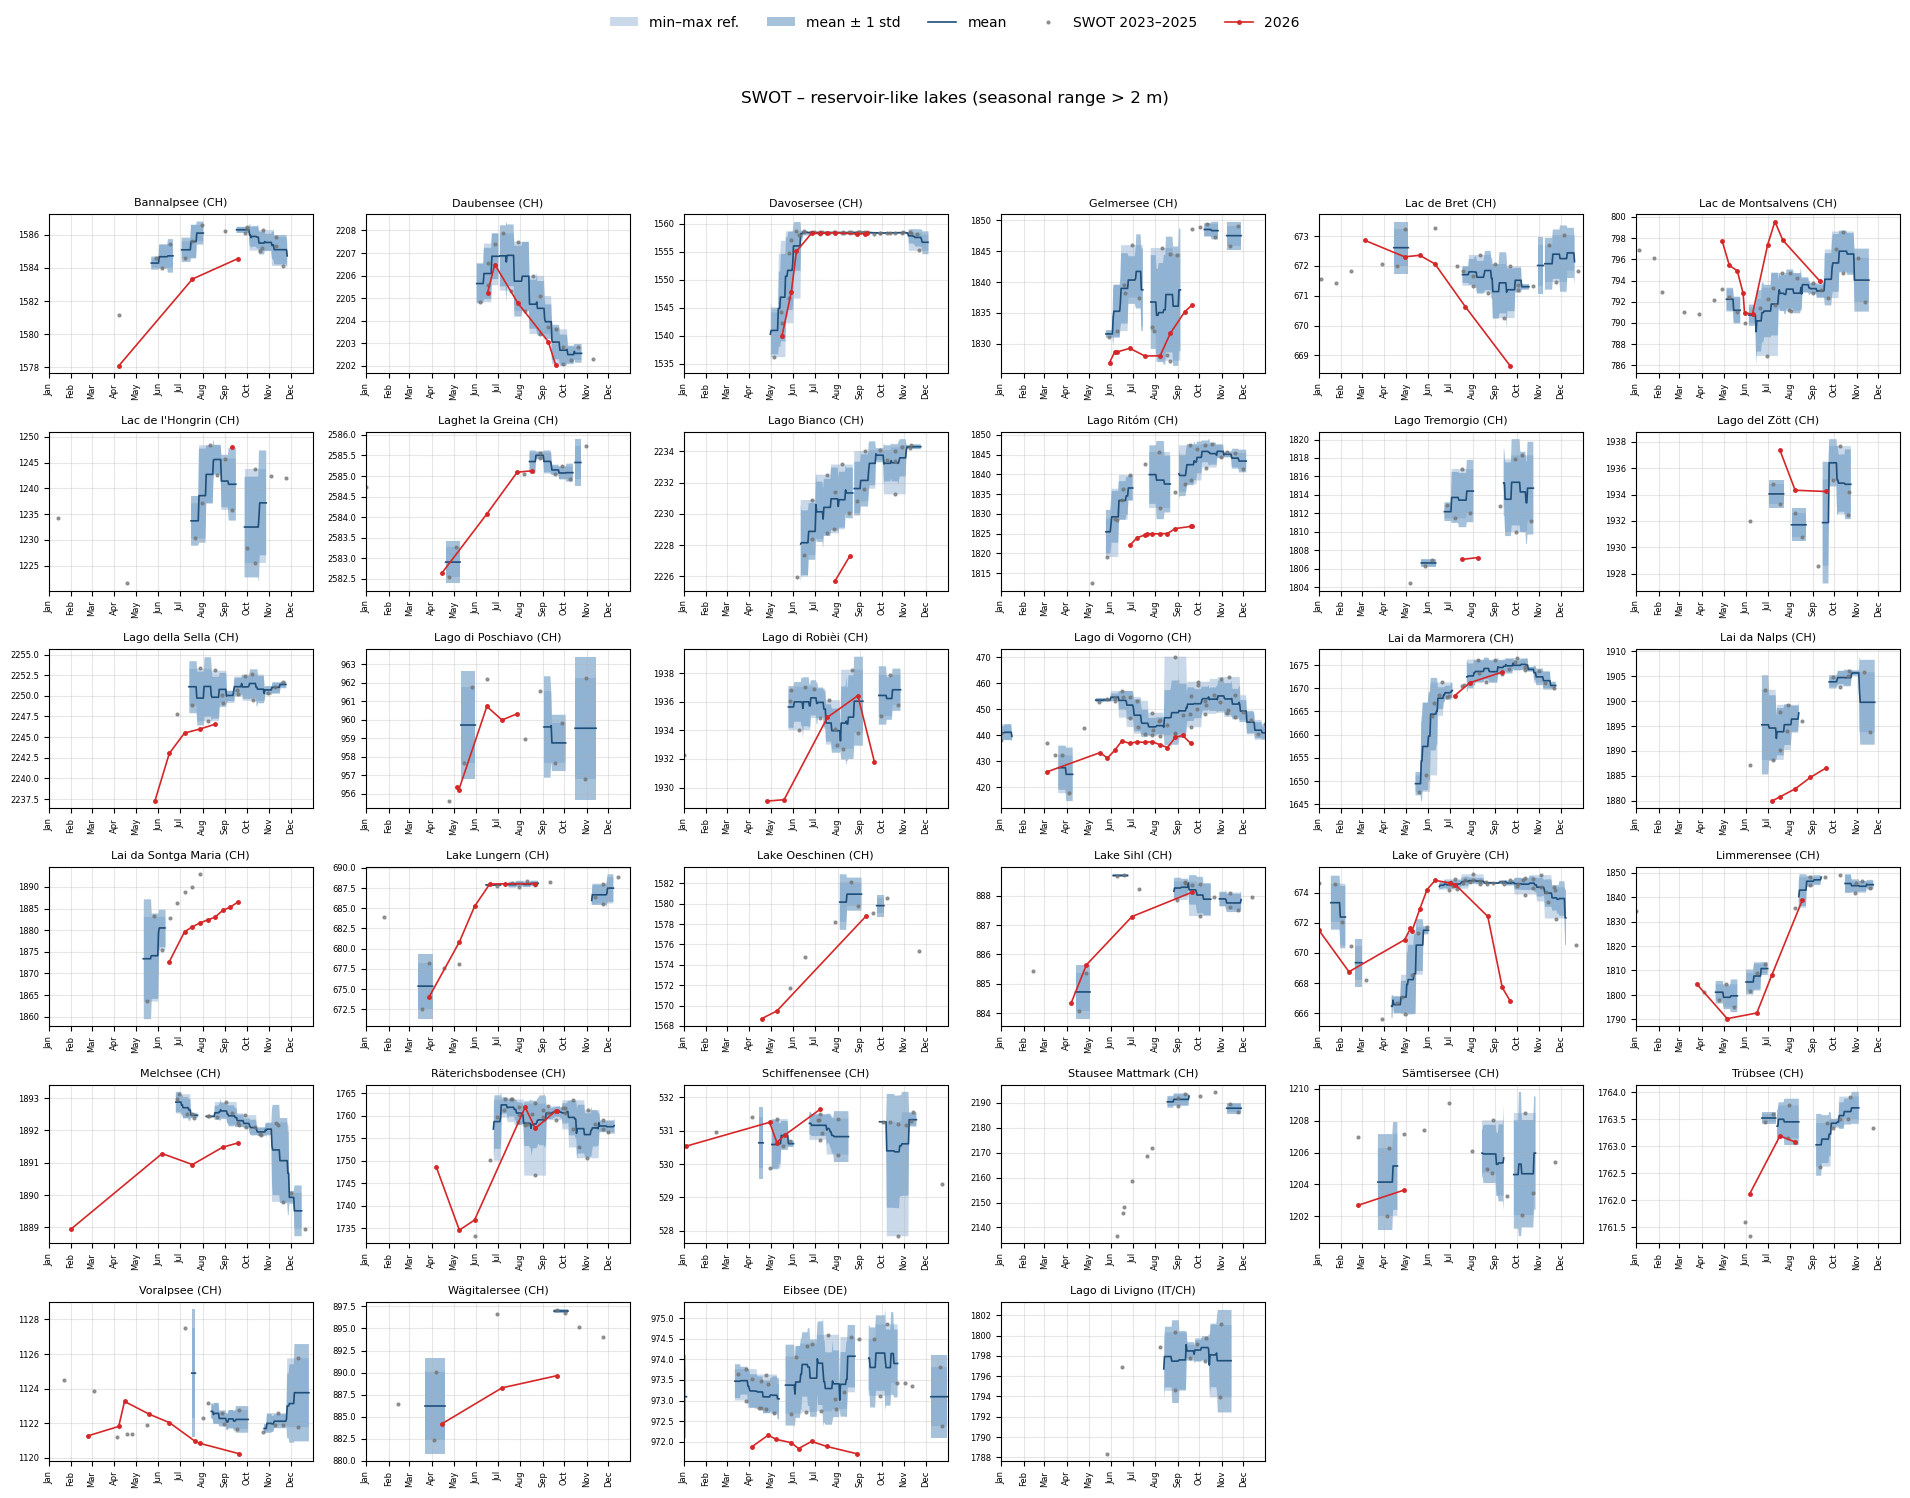

In [22]:
def swot_grid(sub, title, fname, ncol=6):
    nrow = int(np.ceil(len(sub) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 2.5 * nrow), squeeze=False)
    for ax, r in zip(axes.flat, sub.itertuples()):
        plot_swot(r, ax, compact=True)
    for ax in axes.flat[len(sub):]:
        ax.remove()
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, ["min–max ref.", "mean ± 1 std", "mean", "SWOT 2023–2025", str(CURRENT_YEAR)],
               loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title, y=1.0 - 0.35 / nrow, fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / nrow))
    fig.savefig(SWOT_FIG_DIR / fname, dpi=120)
    plt.show()

by_name = swot.sort_values(["country", "name"])
swot_grid(by_name[by_name["type"] == "lake"], "SWOT – natural / weakly regulated lakes", "overview_lakes.png")
swot_grid(by_name[by_name["type"] == "reservoir-like"],
          f"SWOT – reservoir-like lakes (seasonal range > {RESERVOIR_RANGE_M:g} m)", "overview_reservoirs.png")

## Current anomaly: 2026 vs. 2023, 2024, 2025

For each lake, the mean anomaly (observation − reference mean for that calendar day) over the **last 45 days**
before the latest observation is computed for 2026 and, with the same calendar window, for each reference year.
With only three reference years, the question is simply whether 2026 is below all of them.

In [23]:
ANOM_WINDOW_DAYS = 45
last_obs = max(r.data.index.max() for r in swot.itertuples())
w_end = pd.Timestamp(REF_YEAR, last_obs.month, last_obs.day)
w_start = w_end - pd.Timedelta(days=ANOM_WINDOW_DAYS)

rows = []
for r in swot.itertuples():
    if r.clim is None:
        continue
    s = r.data
    ref_day = ref_days(s.index)
    a = pd.Series(s.values - r.clim["mean"].reindex(ref_day).values, index=s.index)
    inwin = (ref_day >= w_start) & (ref_day <= w_end)
    per_year = a[inwin].groupby(a[inwin].index.year).agg(["mean", "count"])
    if CURRENT_YEAR not in per_year.index:
        continue
    for y, v in per_year.iterrows():
        rows.append(dict(name=r.name, country=r.country, type=r.type, year=y, anomaly=v["mean"], n=v["count"]))
swot_anom = pd.DataFrame(rows).dropna(subset=["anomaly"])

cur_a = swot_anom[swot_anom["year"] == CURRENT_YEAR].set_index("name")
ref_a = swot_anom[swot_anom["year"] < CURRENT_YEAR]
cur_a["below_all_ref"] = [cur_a.loc[n, "anomaly"] < ref_a.loc[ref_a["name"] == n, "anomaly"].min()
                          for n in cur_a.index]
cur_a["n_ref_years"] = [ref_a.loc[ref_a["name"] == n, "year"].nunique() for n in cur_a.index]
# comparison needs at least two reference years in the same calendar window
cur_a = cur_a[cur_a["n_ref_years"] >= SWOT_MIN_YEARS]
print(f"Window {w_start:%d %b} – {w_end:%d %b}")
print(cur_a.groupby("type")["below_all_ref"].agg(["sum", "count"])
      .rename(columns={"sum": f"{CURRENT_YEAR} below all ref. years", "count": "lakes"}))
cur_a.sort_values("anomaly")[["country", "type", "anomaly", "n", "n_ref_years", "below_all_ref"]].round(2)

Window 08 Aug – 22 Sep
                2026 below all ref. years  lakes
type                                            
lake                                   24     32
reservoir-like                         11     22


,country,type,anomaly,n,n_ref_years,below_all_ref
name,,,,,,
Lago Ritóm,CH,reservoir-like,-14.35,4.0,2,True
Lago di Vogorno,CH,reservoir-like,-10.55,5.0,3,True
Gelmersee,CH,reservoir-like,-6.62,2.0,2,False
Lake of Gruyère,CH,reservoir-like,-5.69,3.0,3,True
Limmerensee,CH,reservoir-like,-4.03,1.0,2,True
Lago Bianco,CH,reservoir-like,-4.03,1.0,2,True
Lago della Sella,CH,reservoir-like,-3.27,1.0,3,True
Lac de Bret,CH,reservoir-like,-2.55,1.0,3,True
Voralpsee,CH,reservoir-like,-1.99,1.0,2,True


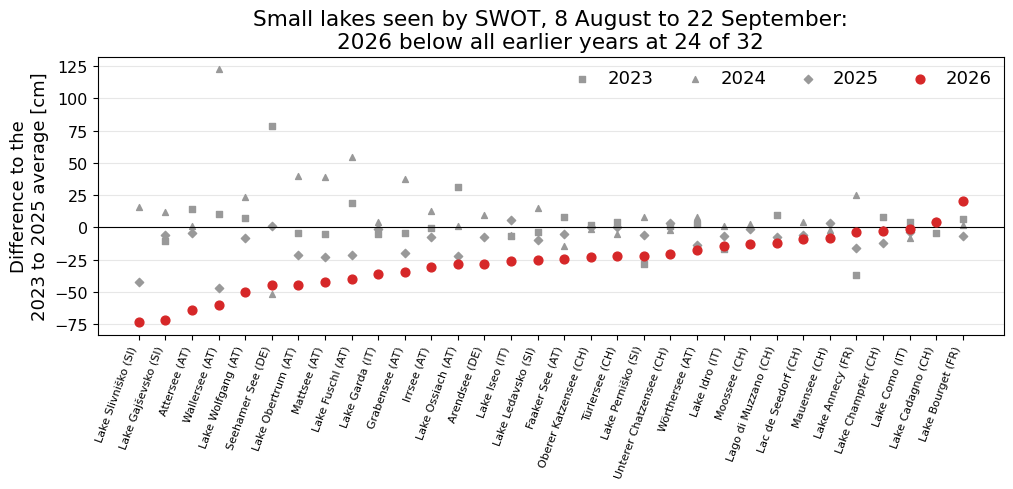

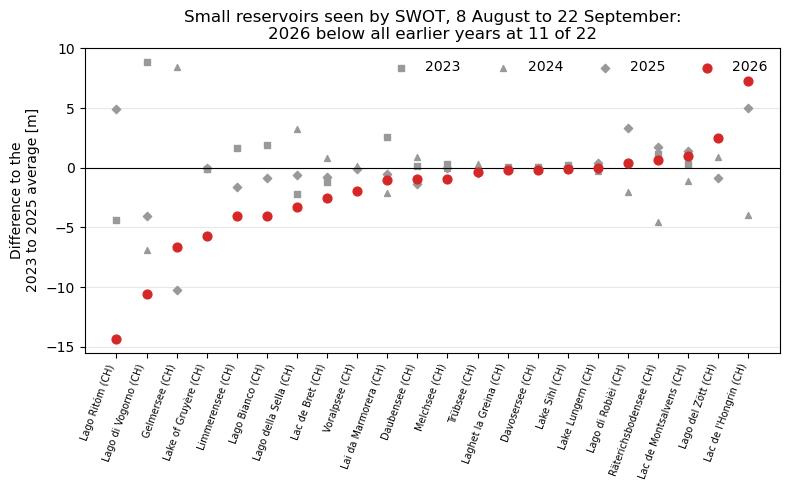

In [24]:
def swot_strip(kind, scale, unit, fname):
    sub = cur_a[cur_a["type"] == kind].sort_values("anomaly")
    fig, ax = plt.subplots(figsize=(max(8, 0.32 * len(sub)), 5))
    markers = {y: m for y, m in zip(sorted(ref_a["year"].unique()), ["s", "^", "D", "v"])}
    for i, name in enumerate(sub.index):
        ra = ref_a[ref_a["name"] == name]
        for y, v in zip(ra["year"], ra["anomaly"]):
            ax.scatter(i, scale * v, marker=markers[y], s=18, color="0.6", zorder=2, label=str(y))
        ax.scatter(i, scale * sub.loc[name, "anomaly"], s=40, color=C_CUR, zorder=3,
                   label=str(CURRENT_YEAR) if i == 0 else None)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(sub)), [f"{n} ({c})" for n, c in zip(sub.index, sub["country"])],
                  rotation=70, ha="right", fontsize=7)
    ax.set_ylabel(f"Difference to the\n2023 to 2025 average [{unit}]")
    n_below = int(sub["below_all_ref"].sum())
    ax.set_title(f"Small {'lakes' if kind == 'lake' else 'reservoirs'} seen by SWOT, {w_start:%-d %B} to {w_end:%-d %B}:\n"
                 f"{CURRENT_YEAR} below all earlier years at {n_below} of {len(sub)}")
    ax.grid(axis="y", alpha=0.3)
    handles, labels = ax.get_legend_handles_labels()
    uniq = dict(sorted(zip(labels, handles), key=lambda t: t[0]))
    ax.legend(uniq.values(), uniq.keys(), frameon=False, loc="upper right", ncol=4)
    fig.tight_layout()
    fig.savefig(SWOT_FIG_DIR / fname, dpi=150)
    plt.show()

swot_strip("lake", 100, "cm", "anomaly_lakes.png")
swot_strip("reservoir-like", 1, "m", "anomaly_reservoirs.png")

# Context figures for the report

## Weather: how dry and how hot was 2026?

Daily precipitation and mean air temperature from the MeteoSwiss automatic network (open data,
[data.geo.admin.ch](https://data.geo.admin.ch/browser/index.html#/collections/ch.meteoschweiz.ogd-smn)).
Two periods are compared with the MeteoSwiss climate normal 1991–2020 (rank: since 1970): winter/spring (1 January – 30 June) and
summer (1 July – latest day).

In [25]:
REPORT_FIG_DIR = FIG_DIR / "report"
REPORT_FIG_DIR.mkdir(exist_ok=True)
METEO_DIR = DATA_DIR / "meteoswiss"
METEO_DIR.mkdir(exist_ok=True)

# station: (label, region), west to east, high Alpine station last
METEO_STATIONS = {
    "GVE": ("Genève", "Lake Geneva"),
    "SIO": ("Sion", "Rhône valley"),
    "NEU": ("Neuchâtel", "Jura lakes"),
    "BER": ("Bern", "Aare, Plateau"),
    "LUZ": ("Luzern", "Lake Lucerne"),
    "SMA": ("Zürich", "Lake Zurich"),
    "STG": ("St. Gallen", "Lake Constance"),
    "LUG": ("Lugano", "Ticino"),
    "SAM": ("Samedan", "Engadin"),
    "GRH": ("Grimsel", "high Alps, 1980 m"),
}
METEO_URL = "https://data.geo.admin.ch/ch.meteoschweiz.ogd-smn/{s}/ogd-smn_{s}_d_{kind}.csv"

def load_meteo(abbr):
    s = abbr.lower()
    frames = []
    for kind in ["historical", "recent"]:
        path = METEO_DIR / f"{s}_d_{kind}.csv"
        if kind == "recent" or not path.exists():   # recent file changes daily
            path.write_bytes(requests.get(METEO_URL.format(s=s, kind=kind), timeout=300).content)
        df = pd.read_csv(path, sep=";", usecols=["reference_timestamp", "tre200d0", "rre150d0"], encoding="latin1")
        frames.append(df)
    df = pd.concat(frames)
    df["date"] = pd.to_datetime(df["reference_timestamp"], format="%d.%m.%Y %H:%M")
    df = df.drop_duplicates("date", keep="last").set_index("date").sort_index()
    return df[["tre200d0", "rre150d0"]].rename(columns={"tre200d0": "T", "rre150d0": "P"})

with ThreadPoolExecutor(MAX_WORKERS) as pool:
    meteo = dict(zip(METEO_STATIONS, pool.map(load_meteo, METEO_STATIONS)))
if REPORT_END is not None:
    meteo = {k: m[:REPORT_END] for k, m in meteo.items()}
meteo_last = min(m.dropna().index.max() for m in meteo.values())
print("latest common day:", meteo_last.date())

latest common day: 2026-09-28


In [26]:
METEO_NORM = (1991, 2020)   # MeteoSwiss climate normal period
PERIODS = {"Jan–Jun": ((1, 1), (6, 30)), f"Jul–{meteo_last:%d %b}": ((7, 1), (meteo_last.month, meteo_last.day))}

def period_stats(m, start, end):
    out = {}
    for y in range(1970, CURRENT_YEAR + 1):
        w = m.loc[pd.Timestamp(y, *start):pd.Timestamp(y, *end)]
        n = (pd.Timestamp(y, *end) - pd.Timestamp(y, *start)).days + 1
        if w["P"].notna().sum() >= 0.95 * n and w["T"].notna().sum() >= 0.95 * n:
            out[y] = {"P": w["P"].sum(), "T": w["T"].mean()}
    return pd.DataFrame(out).T

rows = []
for abbr, (label, region) in METEO_STATIONS.items():
    for pname, (a, b) in PERIODS.items():
        st = period_stats(meteo[abbr], a, b)
        if CURRENT_YEAR not in st.index:
            continue
        ref = st.loc[METEO_NORM[0]:METEO_NORM[1]]
        c = st.loc[CURRENT_YEAR]
        rows.append({"station": label, "region": region, "period": pname,
                     "P_pct": 100 * c["P"] / ref["P"].mean(), "P_rank_dry": int((st["P"] <= c["P"]).sum()),
                     "T_anom": c["T"] - ref["T"].mean(), "T_rank_hot": int((st["T"] >= c["T"]).sum()),
                     "n_years": len(st)})
weather = pd.DataFrame(rows)
weather.round(1)

,station,region,period,P_pct,P_rank_dry,T_anom,T_rank_hot,n_years
0,Genève,Lake Geneva,Jan–Jun,110.2,34,1.6,1,57
1,Genève,Lake Geneva,Jul–28 Sep,50.9,4,3.2,1,57
2,Sion,Rhône valley,Jan–Jun,76.1,13,1.8,1,57
3,Sion,Rhône valley,Jul–28 Sep,90.6,29,2.8,1,57
4,Neuchâtel,Jura lakes,Jan–Jun,75.5,11,1.9,1,57
5,Neuchâtel,Jura lakes,Jul–28 Sep,54.7,3,3.9,1,57
6,Bern,"Aare, Plateau",Jan–Jun,67.2,4,1.7,1,57
7,Bern,"Aare, Plateau",Jul–28 Sep,51.0,1,3.6,1,57
8,Luzern,Lake Lucerne,Jan–Jun,67.5,2,1.5,2,57
9,Luzern,Lake Lucerne,Jul–28 Sep,61.1,5,3.1,1,57


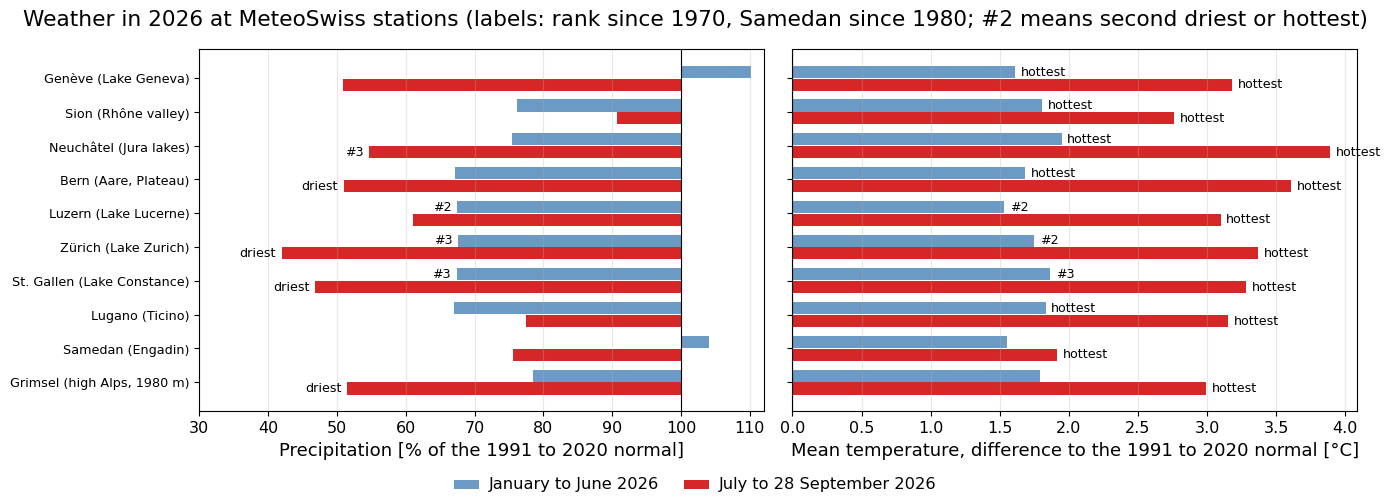

In [27]:
order = [v[0] for v in METEO_STATIONS.values()]
pnames = list(PERIODS)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
y = np.arange(len(order))
for ax, col, xlabel, ref in [(axes[0], "P_pct", f"Precipitation [% of the {METEO_NORM[0]} to {METEO_NORM[1]} normal]", 100),
                             (axes[1], "T_anom", f"Mean temperature, difference to the {METEO_NORM[0]} to {METEO_NORM[1]} normal [°C]", 0)]:
    for k, (pname, color) in enumerate(zip(pnames, [C_STD, C_CUR])):
        d = weather[weather["period"] == pname].set_index("station").reindex(order)
        ax.barh(y + (k - 0.5) * 0.38, d[col] - ref, left=ref, height=0.36, color=color,
                label=(f"January to June {CURRENT_YEAR}" if k == 0 else f"July to {meteo_last:%-d} September {CURRENT_YEAR}"))
        rk = d["P_rank_dry"] if col == "P_pct" else d["T_rank_hot"]
        for yi, v, r, n in zip(y + (k - 0.5) * 0.38, d[col], rk, d["n_years"]):
            if r <= 3:
                ax.annotate("driest" if col == "P_pct" and r == 1 else "hottest" if r == 1 else f"#{r}",
                            (v, yi), xytext=(4 if v >= ref else -4, 0), textcoords="offset points",
                            ha="left" if v >= ref else "right", va="center", fontsize=7)
    ax.axvline(ref, color="k", lw=0.8)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(y, [f"{s} ({METEO_STATIONS[a][1]})" for a, s in zip(METEO_STATIONS, order)], fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlim(30, 112)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, loc="lower center", ncol=2)
fig.suptitle(f"Weather in {CURRENT_YEAR} at MeteoSwiss stations (labels: rank since 1970, Samedan since 1980; #2 means second driest or hottest)")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(REPORT_FIG_DIR / "weather_2026.png", dpi=150)
plt.show()

## Map: where are the lakes low?

Lake outlines from the FOEN VECTOR25 lake layer (`ch.bafu.vec25-seen`). Monitored lakes are coloured by the rank of the 28 September level since 1970; SWOT small natural lakes (triangles) by whether 2026 is below all of 2023–2025.

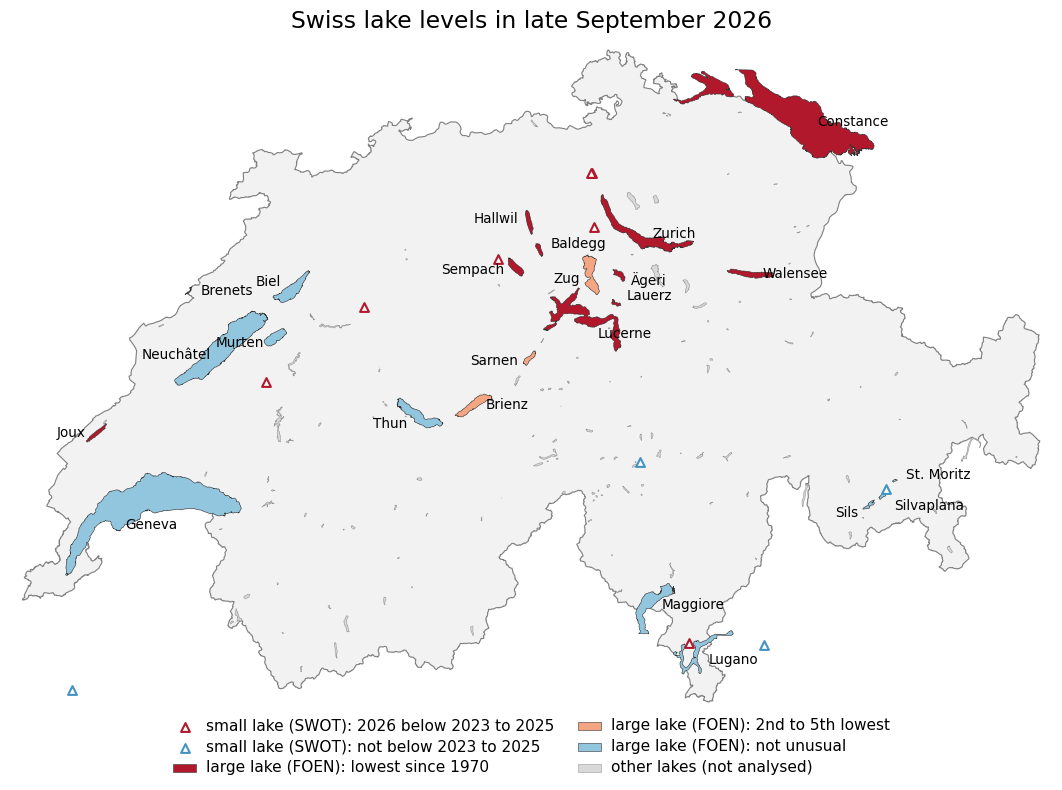

In [28]:
LAKES_URL = "https://api3.geo.admin.ch/rest/services/api/MapServer/identify"
LAKES_PATH = DATA_DIR / "ch_lakes_vec25.json"

def load_lake_layer():
    """FOEN VECTOR25 lake polygons (layer ch.bafu.vec25-seen) with area and regulation flag, cached."""
    if not LAKES_PATH.exists():
        feats, offset = [], 0
        while True:
            res = requests.get(LAKES_URL, timeout=120, params=dict(
                geometryType="esriGeometryEnvelope", geometry="5.8,45.7,10.6,47.9", sr=4326,
                imageDisplay="1000,1000,96", mapExtent="5.8,45.7,10.6,47.9", tolerance=0,
                layers="all:ch.bafu.vec25-seen", returnGeometry="true", geometryFormat="geojson",
                limit=50, offset=offset)).json().get("results", [])
            feats += res
            if len(res) < 50:
                break
            offset += 50
        LAKES_PATH.write_text(json.dumps(feats))
    return json.loads(LAKES_PATH.read_text())

CH_BORDER_URL = ("https://api3.geo.admin.ch/rest/services/api/MapServer/"
                 "ch.swisstopo.swissboundaries3d-land-flaeche.fill/CH?geometryFormat=geojson&sr=4326")
border_path = DATA_DIR / "ch_border.geojson"
if not border_path.exists():
    border_path.write_bytes(requests.get(CH_BORDER_URL, timeout=120).content)
border = json.loads(border_path.read_text())["feature"]["geometry"]["coordinates"]
lake_layer = load_lake_layer()

# FOEN lake (as in `one`) -> name in the VECTOR25 layer; short label shown on the map
VEC25 = {"Baldeggersee": "Baldegger See", "Bielersee": "Bieler See", "Bodensee (Obersee)": "Bodensee",
         "Bodensee (Untersee)": "Untersee", "Brienzersee": "Brienzer See", "Hallwilersee": "Hallwiler See",
         "Lac Léman": "Le Léman", "Lac de Joux": "Lac de Joux", "Lac de Neuchâtel": "Lac de Neuchâtel",
         "Lac des Brenets": "Lac des Brenets", "Lago Maggiore": "Lago Maggiore", "Lago di Lugano": "Lago di Lugano",
         "Lauerzersee": "Lauerzer See", "Murtensee": "Lac de Morat", "Sarnersee": "Sarnersee",
         "Sempachersee": "Sempacher See", "Silsersee": "Lej da Segl", "Silvaplanersee": "Lej da Silvaplauna",
         "St. Moritzersee": "Lej da S. Murezzan", "Thunersee": "Thuner See",
         "Vierwaldstättersee": "Vierwaldstättersee", "Walensee": "Walensee", "Zugersee": "Zuger See",
         "Zürichsee": "Zürichsee", "Zürichsee (Obersee)": "Zürichsee", "Ägerisee": "Ägerisee"}
LABEL = EN
# label offsets in points (dx, dy, ha) where the default (to the right) collides
LABEL_OFFSET = {"Biel": (-8, 6, "right"), "Murten": (-8, -4, "right"), "Neuchâtel": (-10, -6, "right"),
                "Sils": (-8, -6, "right"), "Silvaplana": (8, -8, "left"), "St. Moritz": (8, 4, "left"),
                "Sarnen": (-8, -2, "right"), "Sempach": (-8, -2, "right"), "Hallwil": (-8, 2, "right"),
                "Baldegg": (8, 4, "left"), "Zug": (-8, -4, "right"), "Ägeri": (8, -4, "left"),
                "Lauerz": (8, 5, "left"), "Lucerne": (10, -12, "left"), "Thun": (-8, -6, "right"), "Joux": (-8, 0, "right"),
                "Geneva": (0, -14, "center"), "Maggiore": (8, 0, "left"), "Lugano": (8, -6, "left")}

def ring_centroid(ring):
    x, y = ring[:, 0], ring[:, 1]
    a = x * np.roll(y, -1) - np.roll(x, -1) * y
    A = a.sum() / 2
    return (np.sum((x + np.roll(x, -1)) * a) / (6 * A), np.sum((y + np.roll(y, -1)) * a) / (6 * A)), abs(A)

def lake_rings(feature):
    g = feature["geometry"]
    polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
    return [np.array(p[0]) for p in polys]

def rank_class(r):
    return 0 if r == 1 else 1 if r <= 5 else 2
classes = [("lowest since 1970", "#b2182b"), ("2nd to 5th lowest", "#f4a582"), ("not unusual", "#92c5de")]

lake_rank = {VEC25[lake]: min(rank[l] for l in rank.index if VEC25.get(l) == VEC25[lake])
             for lake in rank.index if lake in VEC25}

fig, ax = plt.subplots(figsize=(12, 8))
for poly in border:
    ring = np.array(poly[0])
    ax.fill(ring[:, 0], ring[:, 1], color="#f2f2f2", zorder=0)
    ax.plot(ring[:, 0], ring[:, 1], color="0.5", lw=0.8, zorder=1)

# all lakes of the layer in light grey, monitored ones coloured by class
for f in lake_layer:
    name = f["properties"]["name"]
    color, ec = ("#d9d9d9", "0.6") if name not in lake_rank else (classes[rank_class(lake_rank[name])][1], "0.2")
    for ring in lake_rings(f):
        ax.fill(ring[:, 0], ring[:, 1], color=color, ec=ec, lw=0.4, zorder=2)

# labels at the centroid of the largest polygon of each monitored lake
done = set()
for lake in rank.index:
    lab = LABEL.get(lake, lake)
    if lake not in VEC25 or lake in ("Bodensee (Untersee)", "Zürichsee (Obersee)") or lab in done:
        continue
    done.add(lab)
    feats = [f for f in lake_layer if f["properties"]["name"] == VEC25[lake]]
    (cx, cy), _ = max((ring_centroid(r) for f in feats for r in lake_rings(f)), key=lambda t: t[1])
    dx, dy, ha = LABEL_OFFSET.get(lab, (8, 0, "left"))
    ax.annotate(lab, (cx, cy), xytext=(dx, dy), textcoords="offset points", fontsize=7.5, ha=ha, va="center",
                zorder=5)

# SWOT small natural lakes
sw = swot[swot["type"] == "lake"].copy()
sw["lat"] = sw["key"].map(lambda k: swot_meta[k]["p_lat"])
sw["lon"] = sw["key"].map(lambda k: swot_meta[k]["p_lon"])
sw["below"] = sw["name"].map(cur_a["below_all_ref"])
sw = sw.dropna(subset=["below"])
for below, color, lab in [(True, "#b2182b", f"small lake (SWOT): {CURRENT_YEAR} below 2023 to 2025"),
                          (False, "#4393c3", "small lake (SWOT): not below 2023 to 2025")]:
    d = sw[sw["below"] == below]
    ax.scatter(d["lon"], d["lat"], marker="^", s=40, facecolor="white", edgecolor=color, lw=1.5, zorder=4, label=lab)

for lab, color in classes:
    ax.fill([], [], color=color, ec="0.2", lw=0.4, label=f"large lake (FOEN): {lab}")
ax.fill([], [], color="#d9d9d9", ec="0.6", lw=0.4, label="other lakes (not analysed)")
ax.set_xlim(5.9, 10.55)
ax.set_ylim(45.8, 47.85)
ax.set_aspect(1 / np.cos(np.radians(46.8)))
ax.set_xticks([])
ax.set_yticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2)
ax.set_title(f"Swiss lake levels in late September {CURRENT_YEAR}", fontsize=13)
fig.tight_layout()
fig.savefig(REPORT_FIG_DIR / "map_2026.png", dpi=150)
plt.show()
